In [1]:
from itertools import product
import pickle
from tqdm import tqdm, trange

import numpy as np
from numpy.linalg import eigh
from scipy.interpolate import interp1d
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.patches import Ellipse
from corner import corner as corner_plot

from scipy import special, stats
from scipy.stats import gaussian_kde, chi2
from scipy.interpolate import RegularGridInterpolator

import os

from local_utils import delaunaytor
from popsummary.popresult import PopulationResult
from astropy.cosmology import Planck15
from astropy import units as u
import popsummary
import plot_funcs_bbh_mass as pf


plt.style.use("tableau-colorblind10")
plt.rcParams["font.family"] = "serif"
plt.rcParams["font.size"] = 14
plt.rcParams["text.usetex"] = True

In [2]:
def q_flat(x):
    ans=1/(5-(-15))

    return ans


def kl_divergence_kde_p_known_q(p_samples, q_pdf, base=np.e, bandwidth='scott'):
    """
    Estimate KL divergence D_KL(P || Q) where:
      - P is only known via samples (estimated with KDE)
      - Q is known analytically via q_pdf(x)
    
    Parameters:
        p_samples (array): 1D array of samples from P
        q_pdf (function): function that returns q(x) given x
        base (float): logarithm base (e.g., np.e or 2)
        bandwidth: bandwidth for KDE (default: 'scott')
    
    Returns:
        float: Estimated KL divergence D_KL(P || Q)
    """
    p_samples = np.asarray(p_samples)
    kde = gaussian_kde(p_samples, bw_method=bandwidth)

    # Evaluate both p(x) and q(x) at the sample points
    p_kde_vals = kde(p_samples)
    q_vals = q_pdf(p_samples)

    # Avoid division by zero or log(0)
    epsilon = 1e-12
    p_kde_vals = np.clip(p_kde_vals, epsilon, None)
    q_vals = np.clip(q_vals, epsilon, None)

    log_ratio = np.log(p_kde_vals / q_vals)
    kl = np.mean(log_ratio)

    return kl / np.log(base)


def kl_divergence_kde(p_samples, q_samples, base=np.e, bandwidth='scott'):
    """
    Estimate delta divergence D_delta(P || Q) where:
      - P is known via samples (estimated with KDE)
      - Q is known via samples (estimated with KDE)
    
    Parameters:
        p_samples (array): 1D array of samples from P
        q_samples (array): 1D array of samples from Q
        base (float): logarithm base (e.g., np.e or 2)
        bandwidth: bandwidth for KDE (default: 'scott')
    
    Returns:
        float: Estimated delta divergence D_delta(P || Q)
    """
    p_samples = np.asarray(p_samples)
    kde_p = gaussian_kde(p_samples, bw_method=bandwidth)

    q_samples = np.asarray(q_samples)
    kde_q = gaussian_kde(q_samples, bw_method=bandwidth)

    # Evaluate both p(x) and q(x) at the sample points
    p_kde_vals = kde_p(p_samples)
    q_kde_vals = kde_q(p_samples)

    # Avoid division by zero or log(0)
    epsilon = 1e-12
    p_kde_vals = np.clip(p_kde_vals, epsilon, None)
    q_kde_vals = np.clip(q_kde_vals, epsilon, None)

    log_ratio = np.log(p_kde_vals / q_kde_vals)
    delta = np.mean(log_ratio)

    return delta / np.log(base)

In [3]:
def smoothing_function(m1, lower, sig):
    smooth = np.zeros_like(m1)
    in_smooth = np.logical_and(m1 >= lower, m1 < lower+sig)
    f = lambda m: np.exp(sig/m + sig/(m-sig))
    smooth[in_smooth] = 1 /(1 + f(m1[in_smooth]-lower))
    smooth[m1>=lower+sig]=1
    return smooth


def power_law_peak(m1, gaussian_params, powlaw_params, smooth_params):
    gauss_pdf = stats.norm(
            loc=gaussian_params[1], scale=gaussian_params[2]
        ).pdf(m1)

    indx, lower, upper = powlaw_params
    norm = (upper**(1 - indx) - lower**(1 - indx)) / (1 - indx)
    powlaw_pdf = m1**(-indx) / norm
    out_bounds = np.logical_or(m1 < lower, m1 > upper)
    powlaw_pdf[out_bounds] = 0

    weight = gaussian_params[0]
    result = weight * gauss_pdf + (1 - weight) * powlaw_pdf

    smooth = smoothing_function(m1, lower, smooth_params)
    return result*smooth

## Use LVK population analysis results as `true' population

In [4]:
gwtc5 = '/home/tristan-bruel/Documents/Science/LVK/gwtc5'
zeval = 0.2
spm_color = '#CD5C5C'
wpm_color = '#2C5AA0'

## DEFAULT PARAMETRIC MODEL ##
strong_bbh_O4b = PopulationResult(fname=f'{gwtc5}/popsummary_files/gwtc5_updated_default_mmax_mass_TwoPeakBrokenPowerLawSmoothedMassDistribution_redshift_PowerLawRedshift_magnitude_iid_spin_magnitude_gaussian_tilt_iid_spin_orientation_popsummary_result.h5')
strong_bbh_O4b_z_grid, strong_bbh_O4b_Rz = strong_bbh_O4b.get_rates_on_grids('redshift')
strong_bbh_O4b_z_grid = strong_bbh_O4b_z_grid.reshape((strong_bbh_O4b_z_grid.size, ))
strong_bbh_O4b_m1_grid, strong_bbh_O4b_Rm1 = strong_bbh_O4b.get_rates_on_grids('mass_1')
strong_bbh_O4b_m1_grid = strong_bbh_O4b_m1_grid.reshape((strong_bbh_O4b_m1_grid.size, ))
strong_bbh_O4b_q_grid, strong_bbh_O4b_Rq = strong_bbh_O4b.get_rates_on_grids('mass_ratio')
strong_bbh_O4b_q_grid = strong_bbh_O4b_q_grid.reshape((strong_bbh_O4b_q_grid.size, ))
redshift_factor_strong_bbh_o4b = (1 + zeval)**(strong_bbh_O4b.get_hyperparameter_samples(hyperparameters=['lamb']))

## PIXELPOP ##
z_pixelpop = PopulationResult(fname=f'{gwtc5}/popsummary_files/may26_datarelease/z_varcut1/z_varcut1_popsummary.h5')
pixelpop_z_grid, pixelpop_Rz = z_pixelpop.get_rates_on_grids('redshift')
pixelpop_z_grid = pixelpop_z_grid.reshape((pixelpop_z_grid.size, ))
m1m2_pixelpop = PopulationResult(fname=f'{gwtc5}/popsummary_files/may26_datarelease/m1m2_varcut1/m1m2_varcut1_popsummary.h5')
(pixelpop_m1_grid, pixelpop_m2_grid), pixelpop_R = m1m2_pixelpop.get_rates_on_grids('joint_pixelpop_rate')
pixelpop_m1_grid, pixelpop_Rm1 = m1m2_pixelpop.get_rates_on_grids('log_mass_1')
pixelpop_m1_grid = pixelpop_m1_grid.reshape((pixelpop_m1_grid.size, ))
redshift_factor_pixelpop_m1 = (1 + zeval)**(m1m2_pixelpop.get_hyperparameter_samples(hyperparameters=['lamb']))
m1q_pixelpop = PopulationResult(fname=f'{gwtc5}/popsummary_files/may26_datarelease/bbh_m1q_varcut1/bbh_m1q_varcut1_popsummary.h5')
pixelpop_q_grid, pixelpop_Rq = m1q_pixelpop.get_rates_on_grids('mass_ratio')
pixelpop_q_grid = pixelpop_q_grid.reshape((pixelpop_q_grid.size, ))
redshift_factor_pixelpop_q = (1 + zeval)**(m1q_pixelpop.get_hyperparameter_samples(hyperparameters=['lamb']))

opening existing popsummary file: /home/tristan-bruel/Documents/Science/LVK/gwtc5/popsummary_files/gwtc5_updated_default_mmax_mass_TwoPeakBrokenPowerLawSmoothedMassDistribution_redshift_PowerLawRedshift_magnitude_iid_spin_magnitude_gaussian_tilt_iid_spin_orientation_popsummary_result.h5
opening existing popsummary file: /home/tristan-bruel/Documents/Science/LVK/gwtc5/popsummary_files/may26_datarelease/z_varcut1/z_varcut1_popsummary.h5
opening existing popsummary file: /home/tristan-bruel/Documents/Science/LVK/gwtc5/popsummary_files/may26_datarelease/m1m2_varcut1/m1m2_varcut1_popsummary.h5
opening existing popsummary file: /home/tristan-bruel/Documents/Science/LVK/gwtc5/popsummary_files/may26_datarelease/bbh_m1q_varcut1/bbh_m1q_varcut1_popsummary.h5


In [5]:
strong_bbh_O4b.get_rates_on_grids_keys()

keys for stored rates on grids are: ['a_1', 'a_2', 'cos_tilt_1', 'cos_tilt_2', 'mass_1', 'mass_ratio', 'redshift']


['a_1', 'a_2', 'cos_tilt_1', 'cos_tilt_2', 'mass_1', 'mass_ratio', 'redshift']

In [6]:
zeval = 0.2

## DEFAULT PARAMETRIC MODEL ##
bivariate_skewnorm = PopulationResult(fname=f'{gwtc5}/popsummary_files/260512_skewNormalChiEffChiP_varcut1/popsummary_var_cut_1.0_with2Drates.h5')
skewnorm_chieff_grid, skewnorm_p_chieff = bivariate_skewnorm.get_rates_on_grids('chi_eff')
skewnorm_chieff_grid = skewnorm_chieff_grid.reshape((skewnorm_chieff_grid.size, ))

## PIXELPOP ##
chieff_chip_pixelpop = PopulationResult(fname=f'{gwtc5}/popsummary_files/may26_datarelease/effective_spins_varcut1/effective_spins_varcut1_popsummary.h5')
pixelpop_chieff_grid, pixelpop_chieff = chieff_chip_pixelpop.get_rates_on_grids('chi_eff')
pixelpop_chieff_grid = pixelpop_chieff_grid.reshape((pixelpop_chieff_grid.size, ))
norm = np.trapezoid(pixelpop_chieff, x=pixelpop_chieff_grid, axis=1)
pixelpop_chieff_norm = pixelpop_chieff / norm[:, None]
redshift_factor_pixelpop_chi = (1 + zeval)**(chieff_chip_pixelpop.get_hyperparameter_samples(hyperparameters=['lamb']))

opening existing popsummary file: /home/tristan-bruel/Documents/Science/LVK/gwtc5/popsummary_files/260512_skewNormalChiEffChiP_varcut1/popsummary_var_cut_1.0_with2Drates.h5
opening existing popsummary file: /home/tristan-bruel/Documents/Science/LVK/gwtc5/popsummary_files/may26_datarelease/effective_spins_varcut1/effective_spins_varcut1_popsummary.h5


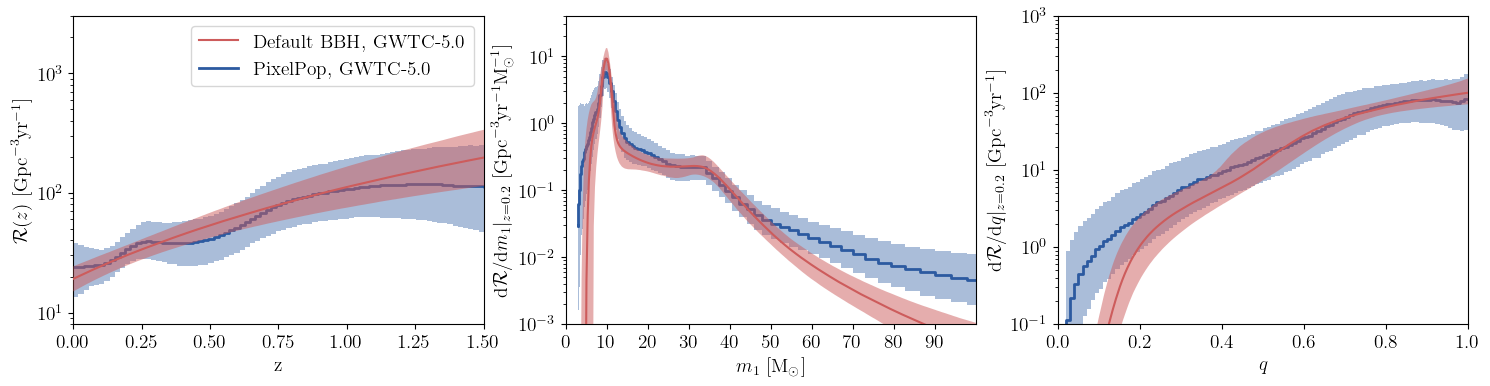

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18,4))

# Merger rate with redshift #
ax = axes[0]
ax.plot(strong_bbh_O4b_z_grid, np.quantile(strong_bbh_O4b_Rz, 0.5, axis = 0),
        color=spm_color, label='Default BBH, GWTC-5.0', lw=1.5, zorder=5)
ax.fill_between(strong_bbh_O4b_z_grid,
        np.quantile(strong_bbh_O4b_Rz, 0.05, axis=0),
        np.quantile(strong_bbh_O4b_Rz, 0.95, axis=0),
        color=spm_color, edgecolor=None, alpha=0.5, zorder=5)
ax.step(pixelpop_z_grid, np.quantile(pixelpop_Rz , 0.5, axis = 0),
        color=wpm_color, label='PixelPop, GWTC-5.0', lw=2.0, zorder=2)
ax.fill_between(pixelpop_z_grid,
        np.quantile(pixelpop_Rz, 0.05, axis = 0),
        np.quantile(pixelpop_Rz, 0.95, axis = 0),
        color=wpm_color, edgecolor=None, alpha=0.4, step='pre', zorder=2)


ax.set_xlabel('z')
ax.set_xlim(xmin=0, xmax=1.5)
ax.set_ylabel(r'$\mathcal{R}(z)\ [\mathrm{Gpc}^{-3} \mathrm{yr}^{-1}]$')
ax.set_yscale('log')
ax.set_ylim(ymin=8, ymax=3e3)
ax.legend()

# Primary mass #
ax = axes[1]
ax.plot(strong_bbh_O4b_m1_grid, np.quantile(redshift_factor_strong_bbh_o4b * strong_bbh_O4b_Rm1, 0.5, axis=0),
        color=spm_color, label='Default BBH, GWTC-5.0', lw=1.5, zorder=5)
ax.fill_between(strong_bbh_O4b_m1_grid,
        np.quantile(redshift_factor_strong_bbh_o4b * strong_bbh_O4b_Rm1, 0.05, axis=0),
        np.quantile(redshift_factor_strong_bbh_o4b * strong_bbh_O4b_Rm1, 0.95, axis=0),
        color=spm_color, edgecolor=None, alpha=0.5, zorder=5)
ax.step(np.exp(pixelpop_m1_grid), np.quantile(redshift_factor_pixelpop_m1 * pixelpop_Rm1 /np.exp(pixelpop_m1_grid) , 0.5, axis = 0),
        color=wpm_color, label='PixelPop, GWTC-5.0', lw=2.0, zorder=2)
ax.fill_between(np.exp(pixelpop_m1_grid),
        np.quantile(redshift_factor_pixelpop_m1 * pixelpop_Rm1 / np.exp(pixelpop_m1_grid) , 0.05, axis = 0),
        np.quantile(redshift_factor_pixelpop_m1 * pixelpop_Rm1 / np.exp(pixelpop_m1_grid), 0.95, axis = 0),
        color=wpm_color, edgecolor=None, alpha=0.4, step='pre', zorder=2)

ax.set_xlabel(r'$m_1\ [\mathrm{M}_\odot]$')
ax.set_xlim(xmin=0, xmax=100)
ax.set_xticks(np.linspace(0,90,10))
ax.set_ylabel(r'$\mathrm{d}\mathcal{R}/\mathrm{d}m_1 |_{z=0.2}\ [\mathrm{Gpc}^{-3} \mathrm{yr}^{-1} \mathrm{M}_\odot^{-1}]$')
ax.set_yscale('log')
ax.set_ylim(ymin=1e-3, ymax=4e1)
#ax.legend(loc='upper right', frameon=False)

# Mass ratio #
ax = axes[2]
ax.plot(strong_bbh_O4b_q_grid, np.quantile(redshift_factor_strong_bbh_o4b * strong_bbh_O4b_Rq, 0.5, axis=0),
        color=spm_color, label='Default BBH, GWTC-5.0', lw=1.5, zorder=5)
ax.fill_between(strong_bbh_O4b_q_grid,
        np.quantile(redshift_factor_strong_bbh_o4b * strong_bbh_O4b_Rq, 0.05, axis=0),
        np.quantile(redshift_factor_strong_bbh_o4b * strong_bbh_O4b_Rq, 0.95, axis=0),
        color=spm_color, edgecolor=None, alpha=0.5, zorder=5)
ax.step(pixelpop_q_grid, np.quantile(redshift_factor_pixelpop_q * pixelpop_Rq, 0.5, axis = 0),
        color=wpm_color, label='PixelPop, GWTC-5.0', lw=2.0, zorder=2)
ax.fill_between(pixelpop_q_grid,
        np.quantile(redshift_factor_pixelpop_q * pixelpop_Rq, 0.05, axis = 0),
        np.quantile(redshift_factor_pixelpop_q * pixelpop_Rq, 0.95, axis = 0),
        color=wpm_color, edgecolor=None, alpha=0.4, step='pre', zorder=2)

ax.set_xlabel(r'$q$')
ax.set_xlim(xmin=0, xmax=1)
ax.set_xticks(np.linspace(0,1,6))
ax.set_ylabel(r'$\mathrm{d}\mathcal{R}/\mathrm{d}q |_{z=0.2}\ [\mathrm{Gpc}^{-3} \mathrm{yr}^{-1}]$')
ax.set_yscale('log')
ax.set_ylim(ymin=1e-1, ymax=1e3)
#ax.legend(loc='upper left', frameon=False)


plt.show()
plt.close()

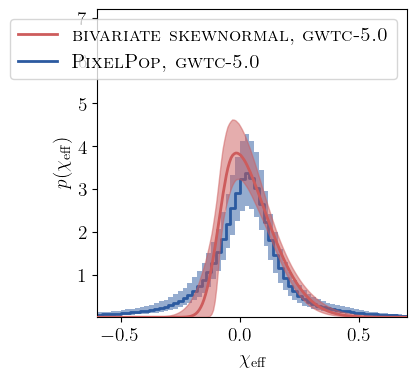

In [8]:
fig, ax = plt.subplots(1, 1, figsize=(4,4))

ax.plot(skewnorm_chieff_grid, np.quantile(skewnorm_p_chieff.T, 0.5, axis = 1), 
         color=spm_color, label='$\\textsc{bivariate skewnormal, gwtc-5.0}$', zorder=5, lw=2.0)  
ax.fill_between(skewnorm_chieff_grid, np.quantile(skewnorm_p_chieff.T, 0.05, axis = 1),
                 np.quantile(skewnorm_p_chieff.T, 0.95, axis = 1), color=spm_color, alpha=0.5, zorder=5) 
ax.step(pixelpop_chieff_grid, np.quantile(pixelpop_chieff_norm, 0.5, axis = 0), 
         color=wpm_color, label='$\\textsc{PixelPop, gwtc-5.0}$', zorder=1, lw=2.0) 
ax.fill_between(pixelpop_chieff_grid, 
                np.quantile(pixelpop_chieff_norm, 0.05, axis = 0), 
                np.quantile(pixelpop_chieff_norm, 0.95, axis = 0), 
                color=wpm_color, edgecolor=None, alpha=0.5, step='pre', zorder=1)


ax.set_xlabel(r'$\chi_\mathrm{eff}$')
ax.set_xlim([-0.6, 0.7])
ax.set_ylabel(r'$p(\chi_\mathrm{eff})$')
ax.set_ylim([0,  7.2])
ax.set_yticks([1, 2, 3, 4, 5, 6, 7])
ax.legend()

plt.show()
plt.close()

In [9]:
strong_bbh_O4b_Rm1.shape

(8200, 1000)

In [10]:
strong_bbh_O4b_Rq.shape

(8200, 500)

In [11]:
skewnorm_p_chieff.shape

(3881, 300)

In [12]:
zeval=0.2
redshift_factor_strong_bbh_o4b = (1 + zeval)**(strong_bbh_O4b.get_hyperparameter_samples(hyperparameters=['lamb']))
print('R(z=%.1f), integral dR/dm1, integral dR/dq, integral dR/dchi' %zeval)
for ind in range(3):
    Rzeval = interp1d(strong_bbh_O4b_z_grid, strong_bbh_O4b_Rz[ind,:], fill_value='extrapolate')(zeval)
    int_dRdm1 = np.trapezoid(x=strong_bbh_O4b_m1_grid, y=(redshift_factor_strong_bbh_o4b * strong_bbh_O4b_Rm1)[ind])
    int_dRdq = np.trapezoid(x=strong_bbh_O4b_q_grid, y=(redshift_factor_strong_bbh_o4b * strong_bbh_O4b_Rq)[ind])
    int_dRdchi = np.trapezoid(x=skewnorm_chieff_grid, y=skewnorm_p_chieff[ind])
    print(Rzeval, int_dRdm1, int_dRdq, int_dRdchi)

R(z=0.2), integral dR/dm1, integral dR/dq, integral dR/dchi
43.85726547616642 43.85646880807036 43.85646880807036 1.000000013464133
28.035447937840907 28.035349171744507 28.035349171744503 0.9999999824842349
32.88557393041641 32.88561532054052 32.88561532054052 0.999999939250289


In [13]:
zeval=0.2
redshift_factor_pixelpop_m1 = (1 + zeval)**(m1m2_pixelpop.get_hyperparameter_samples(hyperparameters=['lamb']))
redshift_factor_pixelpop_q = (1 + zeval)**(m1q_pixelpop.get_hyperparameter_samples(hyperparameters=['lamb']))
redshift_factor_pixelpop_chi = (1 + zeval)**(chieff_chip_pixelpop.get_hyperparameter_samples(hyperparameters=['lamb']))
print('R(z=%.1f), integral dR/dm1, integral dR/dq, integral dR/dchi' %zeval)
for ind in range(3):
    Rzeval = interp1d(pixelpop_z_grid, pixelpop_Rz[ind,:], fill_value='extrapolate')(zeval)
    int_dRdm1 = np.trapezoid(x=np.exp(pixelpop_m1_grid), y=(redshift_factor_pixelpop_m1 * pixelpop_Rm1 /np.exp(pixelpop_m1_grid))[ind])
    int_dRdq = np.trapezoid(x=pixelpop_q_grid, y=(redshift_factor_pixelpop_q * pixelpop_Rq)[ind])
    int_dRdchi = np.trapezoid(x=pixelpop_chieff_grid, y=(redshift_factor_pixelpop_chi * pixelpop_chieff)[ind])
    print(Rzeval, int_dRdm1, int_dRdq, int_dRdchi)

R(z=0.2), integral dR/dm1, integral dR/dq, integral dR/dchi
49.52904671116879 34.48919 30.625787943117317 30.666123576164242
31.150501953928096 25.803457 27.61418243966997 23.127844141721727
26.166643644634043 36.00839 31.90534793037921 27.15968297958374


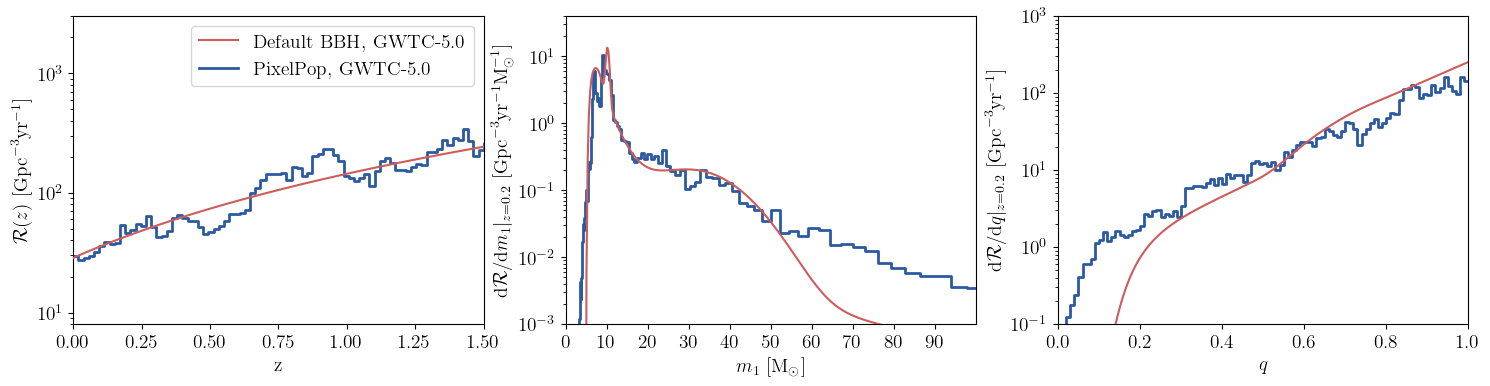

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(18,4))

# Merger rate with redshift #
ind=0
ax = axes[0]
ax.plot(strong_bbh_O4b_z_grid, strong_bbh_O4b_Rz[ind],
        color=spm_color, label='Default BBH, GWTC-5.0', lw=1.5, zorder=5)
ax.step(pixelpop_z_grid, pixelpop_Rz[ind],
        color=wpm_color, label='PixelPop, GWTC-5.0', lw=2.0, zorder=2)


ax.set_xlabel('z')
ax.set_xlim(xmin=0, xmax=1.5)
ax.set_ylabel(r'$\mathcal{R}(z)\ [\mathrm{Gpc}^{-3} \mathrm{yr}^{-1}]$')
ax.set_yscale('log')
ax.set_ylim(ymin=8, ymax=3e3)
ax.legend()

# Primary mass #
ax = axes[1]
ax.plot(strong_bbh_O4b_m1_grid, (redshift_factor_strong_bbh_o4b * strong_bbh_O4b_Rm1)[ind],
        color=spm_color, label='Default BBH, GWTC-5.0', lw=1.5, zorder=5)
ax.step(np.exp(pixelpop_m1_grid), (redshift_factor_pixelpop_m1 * pixelpop_Rm1 /np.exp(pixelpop_m1_grid))[ind],
        color=wpm_color, label='PixelPop, GWTC-5.0', lw=2.0, zorder=2)

ax.set_xlabel(r'$m_1\ [\mathrm{M}_\odot]$')
ax.set_xlim(xmin=0, xmax=100)
ax.set_xticks(np.linspace(0,90,10))
ax.set_ylabel(r'$\mathrm{d}\mathcal{R}/\mathrm{d}m_1 |_{z=0.2}\ [\mathrm{Gpc}^{-3} \mathrm{yr}^{-1} \mathrm{M}_\odot^{-1}]$')
ax.set_yscale('log')
ax.set_ylim(ymin=1e-3, ymax=4e1)
#ax.legend(loc='upper right', frameon=False)

# Mass ratio #
ax = axes[2]
ax.plot(strong_bbh_O4b_q_grid, (redshift_factor_strong_bbh_o4b * strong_bbh_O4b_Rq)[ind],
        color=spm_color, label='Default BBH, GWTC-5.0', lw=1.5, zorder=5)
ax.step(pixelpop_q_grid, (redshift_factor_pixelpop_q * pixelpop_Rq)[ind],
        color=wpm_color, label='PixelPop, GWTC-5.0', lw=2.0, zorder=2)

ax.set_xlabel(r'$q$')
ax.set_xlim(xmin=0, xmax=1)
ax.set_xticks(np.linspace(0,1,6))
ax.set_ylabel(r'$\mathrm{d}\mathcal{R}/\mathrm{d}q |_{z=0.2}\ [\mathrm{Gpc}^{-3} \mathrm{yr}^{-1}]$')
ax.set_yscale('log')
ax.set_ylim(ymin=1e-1, ymax=1e3)
#ax.legend(loc='upper left', frameon=False)


plt.show()
plt.close()

## GW events

In [15]:
parameter_keys = ["m1", "z", "q", "chi_eff"]

data_file = np.load("./z_m1_q_chi_eff/gwtc5_samples_chieff.npz")
observed_events = np.vstack([data_file[key + "s"] for key in parameter_keys]).T
num_events = data_file["nevents"]
num_samples = data_file["nsamples"]
event_priors = data_file["priors"]
print(
        f"Running with {num_events} events × {num_samples} samples = {num_events*num_samples} total samples"
    )

event_barycenters = observed_events.reshape(
    (num_events, num_samples, observed_events.shape[-1])
).mean(axis=1)

Running with 259 events × 3194 samples = 827246 total samples


## Triangulation setup

In [16]:
z_min = 1e-6
z_max = 1.5
m1_min = 3.0
m1_max = 150.0
q_min = 0.
q_max = 1.
chi_eff_min = -1.
chi_eff_max = 1.

w_min = -20
w_max = 15
nvertices_min = 4
nvertices_max = 100

corners = np.array([
        [m1_min, z_min, q_min, chi_eff_min],
        [m1_min, z_min, q_min, chi_eff_max],
        [m1_min, z_min, q_max, chi_eff_min],
        [m1_min, z_min, q_max, chi_eff_max],
        [m1_min, z_max, q_min, chi_eff_min],
        [m1_min, z_max, q_min, chi_eff_max],
        [m1_min, z_max, q_max, chi_eff_min],
        [m1_min, z_max, q_max, chi_eff_max],
        [m1_max, z_min, q_min, chi_eff_min],
        [m1_max, z_min, q_min, chi_eff_max],
        [m1_max, z_min, q_max, chi_eff_min],
        [m1_max, z_min, q_max, chi_eff_max],
        [m1_max, z_max, q_min, chi_eff_min],
        [m1_max, z_max, q_min, chi_eff_max],
        [m1_max, z_max, q_max, chi_eff_min],
        [m1_max, z_max, q_max, chi_eff_max],
    ])

print(corners)

[[ 3.0e+00  1.0e-06  0.0e+00 -1.0e+00]
 [ 3.0e+00  1.0e-06  0.0e+00  1.0e+00]
 [ 3.0e+00  1.0e-06  1.0e+00 -1.0e+00]
 [ 3.0e+00  1.0e-06  1.0e+00  1.0e+00]
 [ 3.0e+00  1.5e+00  0.0e+00 -1.0e+00]
 [ 3.0e+00  1.5e+00  0.0e+00  1.0e+00]
 [ 3.0e+00  1.5e+00  1.0e+00 -1.0e+00]
 [ 3.0e+00  1.5e+00  1.0e+00  1.0e+00]
 [ 1.5e+02  1.0e-06  0.0e+00 -1.0e+00]
 [ 1.5e+02  1.0e-06  0.0e+00  1.0e+00]
 [ 1.5e+02  1.0e-06  1.0e+00 -1.0e+00]
 [ 1.5e+02  1.0e-06  1.0e+00  1.0e+00]
 [ 1.5e+02  1.5e+00  0.0e+00 -1.0e+00]
 [ 1.5e+02  1.5e+00  0.0e+00  1.0e+00]
 [ 1.5e+02  1.5e+00  1.0e+00 -1.0e+00]
 [ 1.5e+02  1.5e+00  1.0e+00  1.0e+00]]


## Some diagnostics of the sampling

In [17]:
backend_file = 'z_m1_q_chi_eff/backend'
with open(backend_file, "rb") as f:
    back = pickle.load(f)
ntemps = back.ntemps
nwalkers = back.nwalkers
nsteps = back.chain['tri'].shape[0]
tri_sizes = np.array([
        back.inds["tri"][step, 0, walker].sum()
        for step, walker in product(range(nsteps), range(nwalkers))
        ])

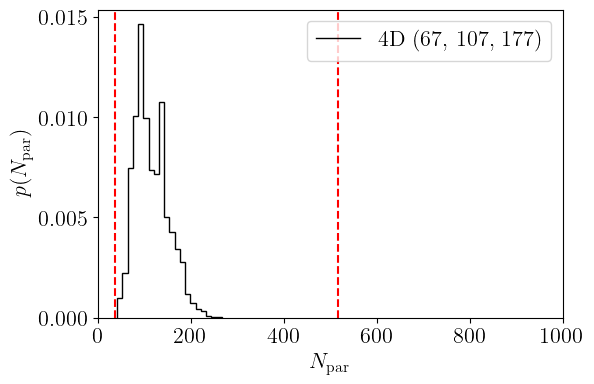

In [18]:
fig, ax = plt.subplots(figsize=(6,4))
ax.set(
    yscale="linear",
    xlabel=r"$N_{\mathrm{par}}$",
    ylabel=r"$p(N_{\mathrm{par}})$",
    xlim=(0, 1_000),
)

ls = ["-", "--", ":"]

ind=0
ndim=4
offset=2**ndim

n_params = tri_sizes * (ndim + 1) + offset + 1

l, m, h = np.quantile(n_params, [0.05, 0.5, 0.95]).astype(int)

hist, edges = np.histogram(n_params, density=True, bins=20)
ax.stairs(
    hist,
    edges, 
    color='black', 
    ls=ls[ind], 
    label=f"{ndim}D ({l}, {m}, {h})"
)

ax.axvline(nvertices_min * (ndim + 1) + offset + 1, color='r', linestyle='--')
ax.axvline(nvertices_max * (ndim + 1) + offset + 1, color='r', linestyle='--')

ax.legend()
plt.show()
plt.close()

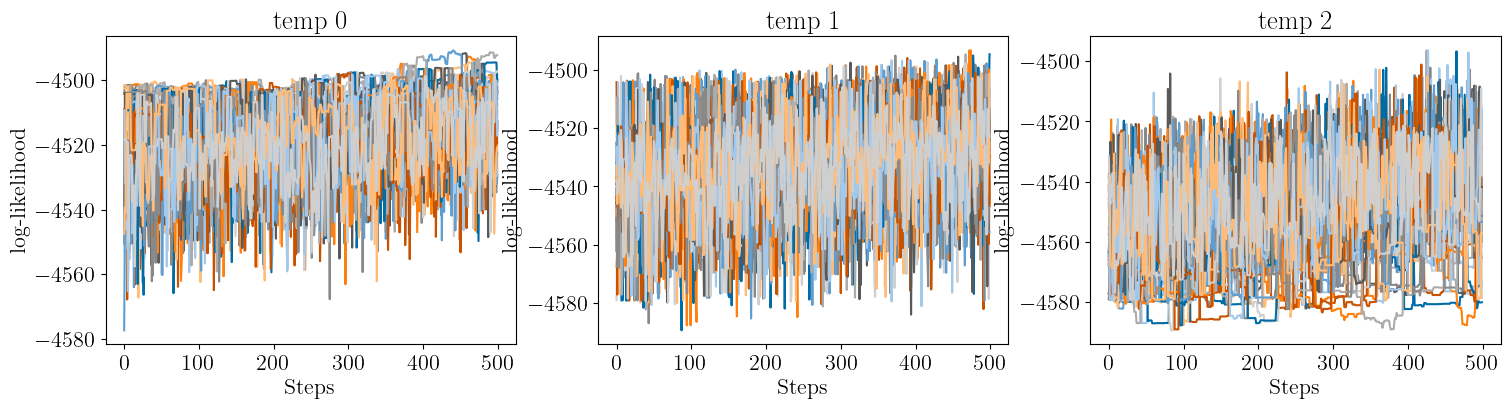

In [19]:
fig, axes = plt.subplots(1, ntemps, figsize=(18,4))
for t,w in product(range(ntemps),range(nwalkers)):
    ax = axes[t]
    ax.plot(back.get_log_like()[:, t, w])
    ax.set(title=f"temp {t}")
    ax.set_xlabel(r"Steps")
    ax.set_ylabel(r"log-likelihood")
plt.show()
plt.close()

In [20]:
nburn = 400

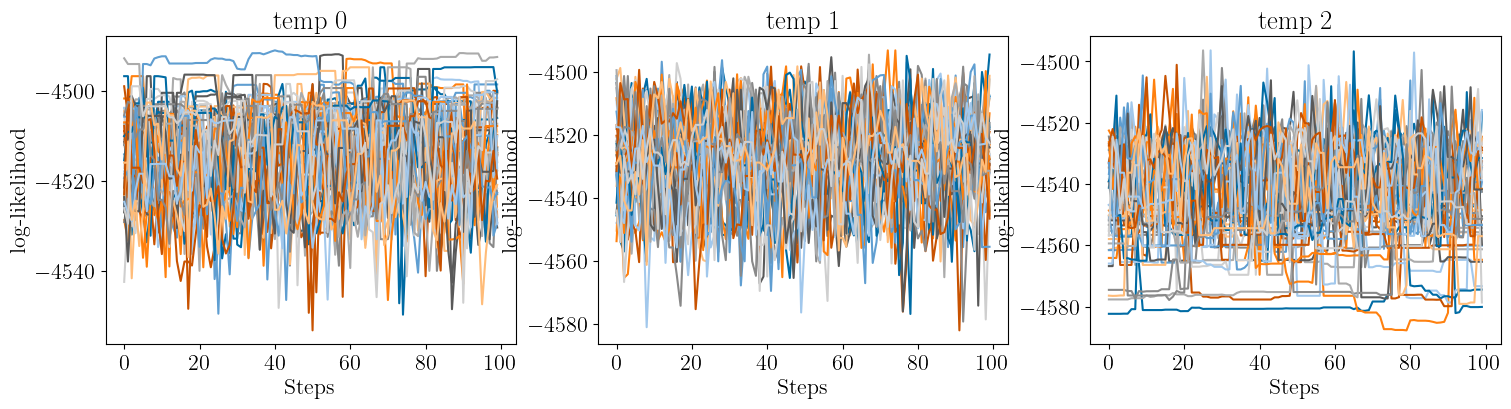

In [21]:
fig, axes = plt.subplots(1, ntemps, figsize=(18,4))
for t,w in product(range(ntemps),range(nwalkers)):
    ax = axes[t]
    ax.plot(back.get_log_like()[nburn:, t, w])
    ax.set(title=f"temp {t}")
    ax.set_xlabel(r"Steps")
    ax.set_ylabel(r"log-likelihood")
plt.show()
plt.close()

<>:12: SyntaxWarning: invalid escape sequence '\c'
<>:12: SyntaxWarning: invalid escape sequence '\c'
/tmp/ipykernel_32988/2188773455.py:12: SyntaxWarning: invalid escape sequence '\c'
  +", $q=%.1f$, $\chi_\mathrm{eff}=%.1f$"


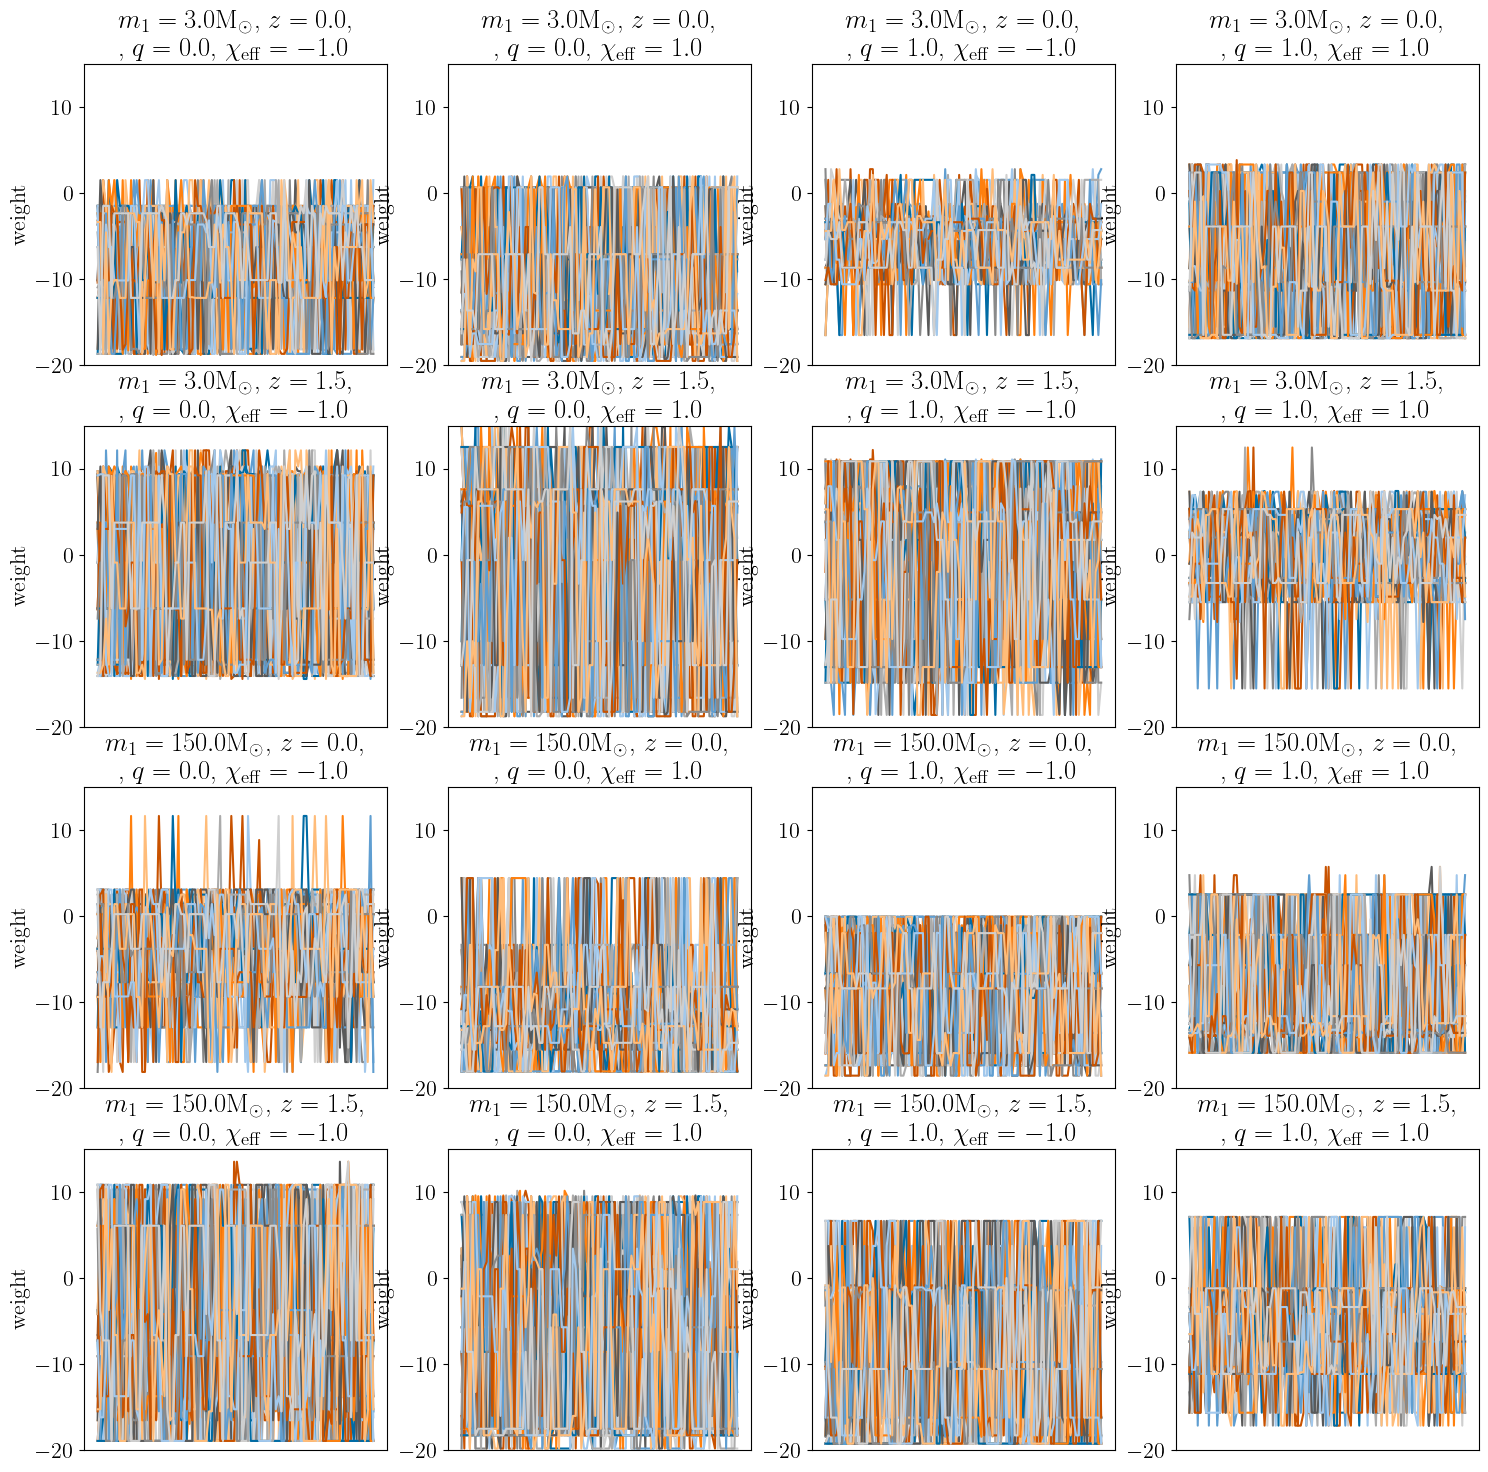

In [22]:
fig, axes = plt.subplots(4, 4, figsize=(18,18))
for n in range(len(corners)):
    ax = axes[n//4, n%4]
    # for t,w in product(range(ntemps-1),range(nwalkers)):
    #     ax.plot(np.ravel(back.chain['corner_w'][nburn:,t,w,0,n]))
    t=0
    for w in range(nwalkers):
        ax.plot(np.ravel(back.chain['corner_w'][nburn:,t,w,0,n]))
    ax.set(title=r"$m_1=%.1f\mathrm{M}_\odot$, $z=%.1f$,"  
            %(corners[n][0],corners[n][1])
            +'\n'
            +", $q=%.1f$, $\chi_\mathrm{eff}=%.1f$"
            %(corners[n][2],corners[n][3]))
    #ax.set_xlabel(r"Steps")
    ax.set_ylabel(r"weight")
    ax.set_xticks([])
    ax.set_ylim(w_min,w_max)
plt.show()
plt.close()

## Load triangulations

In [23]:
all_triangulations = []
for t in range(ntemps):
    triangulations = [
        back.chain["tri"][step, t, walker][back.inds["tri"][step, t, walker]]
        for step, walker in product(range(nburn,nsteps), range(nwalkers))
    ]
    corner_weights = np.array(
        [
            back.chain["corner_w"][step, t, walker]
            for step, walker in product(range(nburn,nsteps), range(nwalkers))
        ]
    )
    for ind in tqdm(range(len(triangulations))):
        all_triangulations.extend([
            np.vstack([triangulations[ind], np.c_[corners, corner_weights[ind].T]])                
        ])
### KEEP ONLY FIRST TEMPERATURE FOR NOW ###
# t=0
# triangulations = [
#     back.chain["tri"][step, t, walker][back.inds["tri"][step, t, walker]]
#     for step, walker in product(range(nburn,nsteps), range(nwalkers))
# ]
# corner_weights = np.array(
#     [
#         back.chain["corner_w"][step, t, walker]
#         for step, walker in product(range(nburn,nsteps), range(nwalkers))
#     ]
# )
# for ind in tqdm(range(len(triangulations))):
#     all_triangulations.extend([
#         np.vstack([triangulations[ind], np.c_[corners, corner_weights[ind].T]])                
#     ])

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 4000/4000 [00:00<00:00, 217518.68it/s]


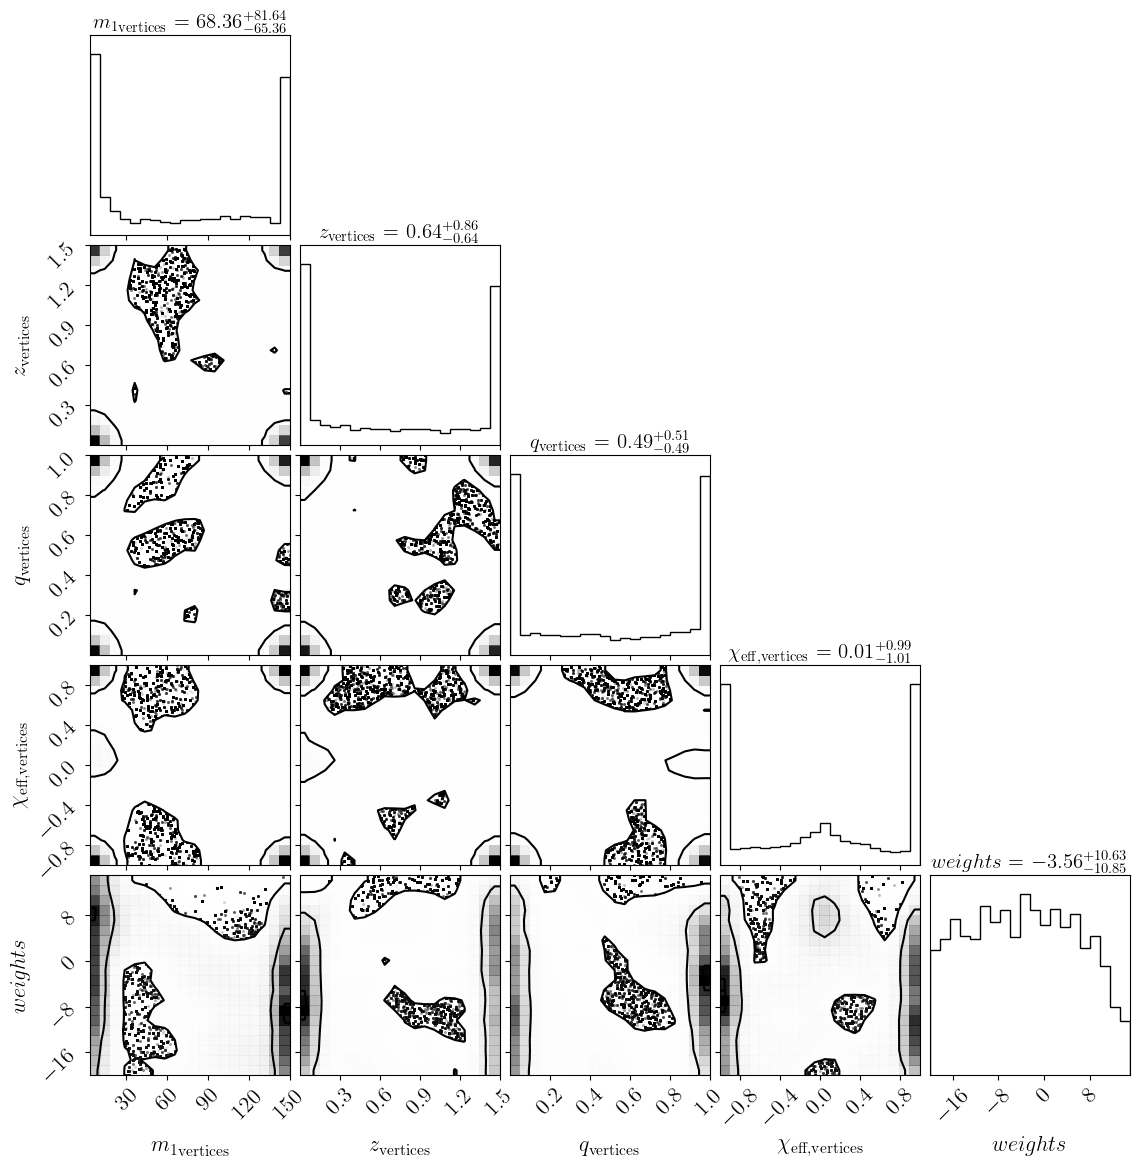

In [24]:
ws = np.hstack([tri[:, -1] for tri in all_triangulations])
vertices = np.vstack([tri[:, :-1] for tri in all_triangulations])    
corner_plot(np.c_[vertices, ws], smooth=True, levels=[0.05, 0.5, 0.95],
            labels=[r"${m_1}_\mathrm{vertices}$", 
                    r"$z_\mathrm{vertices}$", 
                    r"$q_\mathrm{vertices}$", 
                    r"$\chi_\mathrm{eff,vertices}$", 
                    r"$weights$"],
            show_titles=True,
            title_kwargs={"fontsize": 15},
           )
plt.show()
plt.close()

In [25]:
## Evolution of the inferred rate at fixed points ##
targets = np.array([[10.,0.2,0.8,0.0],[35.,0.2,0.8,0.0],[35.,1.0,0.8,0.0],[35.,0.2,0.5,0.0]])
selected_tris = np.random.choice(len(all_triangulations), size=1000, replace=False)
num_triangulations = len(selected_tris)

log_rate_at_target = np.zeros((num_triangulations,4))

for ind, tri_ind in enumerate(tqdm(selected_tris)):
    this_delo = delaunaytor.CPUDelaunayInterpolator()
    this_delo.triangulate(all_triangulations[tri_ind])
    log_rate_at_target[ind] = this_delo.interpolate(targets)

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1000/1000 [00:03<00:00, 324.57it/s]


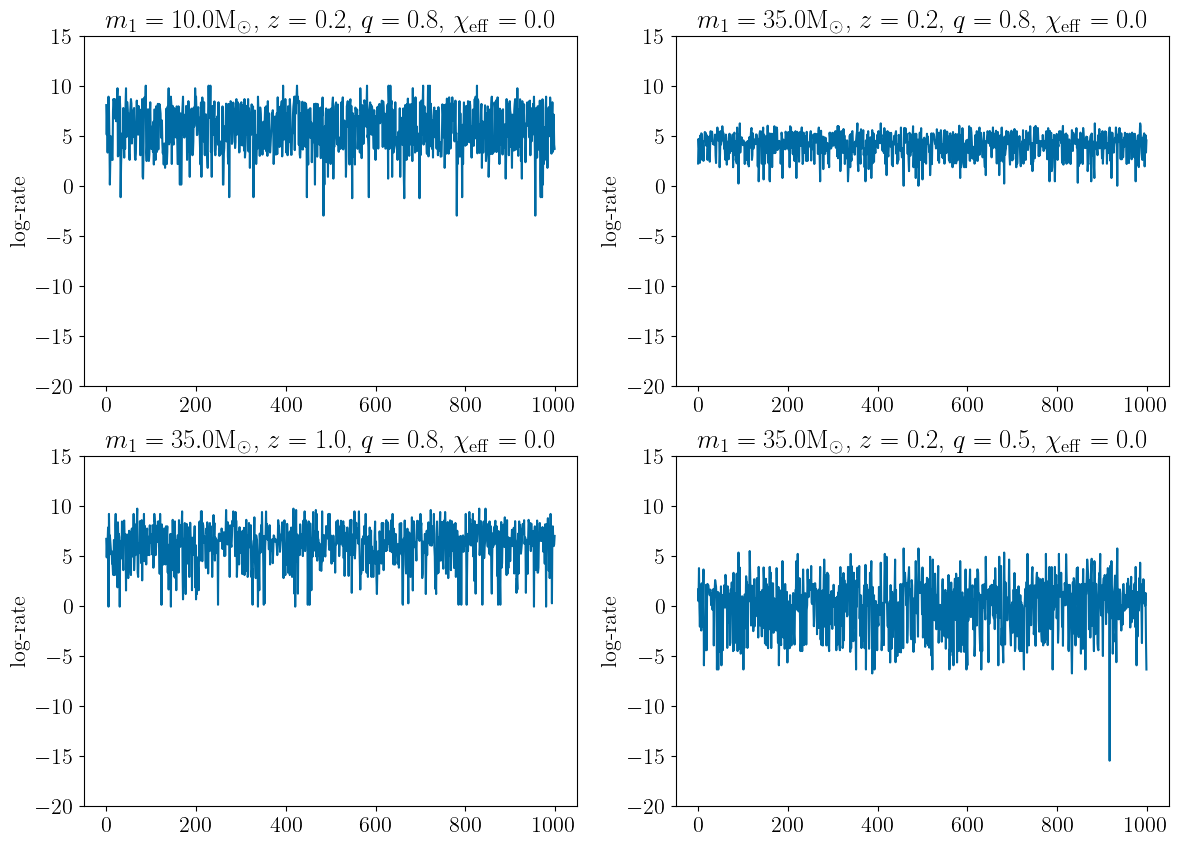

In [26]:
fig, axes = plt.subplots(2, 2, figsize=(14,10))
for n in range(len(targets)):
    ax = axes[n//2, n%2]
    ax.plot(log_rate_at_target[:,n])
    ax.set(title=r"$m_1=%.1f\mathrm{M}_\odot$, $z=%.1f$, $q=%.1f$, $\chi_\mathrm{eff}=%.1f$" 
           %(targets[n][0],targets[n][1],targets[n][2],targets[n][3]))
    #ax.set_xlabel(r"Steps")
    ax.set_ylabel(r"log-rate")
    ax.set_ylim(w_min,w_max)
plt.show()
plt.close()

### Injections

In [27]:
injections_file = np.load("./z_m1_q_chi_eff/gwtc5_injections_full_chieff.npz")
detected_injections = np.vstack(
    [injections_file[key + "s"] for key in parameter_keys]
).T
injection_priors = injections_file["inj_priors"]
num_injections = int(injections_file["ninjs"])
Tobs = injections_file['analysis_time'] # in years

In [28]:
print('Total time of the combined runs: %.3f years' %Tobs)
print('Total number of injections for GWTC-3: %.2e' %num_injections)
print('Number of detected injections for GWTC-3: %.2e' %detected_injections.shape[0])

Total time of the combined runs: 3.046 years
Total number of injections for GWTC-3: 1.57e+09
Number of detected injections for GWTC-3: 1.58e+06


## Compute rate over grids

In [29]:
# m1_grid = np.linspace(m1_min, m1_max, 22)
# z_grid = np.linspace(0.05, z_max, 21)
# q_grid = np.linspace(q_min, q_max, 20)
# chi_grid = np.linspace(chi_eff_min, chi_eff_max, 19)

# X, Y, Z, T = np.meshgrid(m1_grid, z_grid, q_grid, chi_grid)
# grid = np.c_[X.ravel(), Y.ravel(), Z.ravel(), T.ravel()]

# dm1 = m1_grid[1] - m1_grid[0]
# dz = z_grid[1] - z_grid[0]
# dq = q_grid[1] - q_grid[0]
# dchi = chi_grid[1] - chi_grid[0]

# to_comoving_volume = (1 + z_grid) / (
#         4 * np.pi * Tobs * Planck15.differential_comoving_volume(z_grid).to(u.Gpc**3 / u.sr).value
#     )

In [30]:
# selected_tris = np.random.choice(len(all_triangulations), size=1000, replace=False)
# num_triangulations = len(selected_tris)

# log_rate = np.zeros((num_triangulations, grid.shape[0]))

# for ind, tri_ind in enumerate(tqdm(selected_tris)):
#     this_delo = delaunaytor.CPUDelaunayInterpolator()
#     this_delo.triangulate(all_triangulations[tri_ind])
#     log_rate[ind] = this_delo.interpolate(grid)
    
# square_rate = log_rate.reshape(num_triangulations, z_grid.shape[0], m1_grid.shape[0], q_grid.shape[0], chi_grid.shape[0])

## Prior

In [31]:
# nsamples_prior = 1_000
# log_rate_prior = np.zeros((nsamples_prior, grid.shape[0]))

# for i in tqdm(range(nsamples_prior)):
#     nleaves_i = np.random.randint(nvertices_min, nvertices_max)
#     tri_i = np.zeros((nleaves_i+offset,ndim+1))
#     tri_i[:offset,:-1] = corners
#     tri_i[offset:,0] = np.random.uniform(m1_min, m1_max, nleaves_i)
#     tri_i[offset:,1] = np.random.uniform(z_min, z_max, nleaves_i)
#     tri_i[offset:,2] = np.random.uniform(q_min, q_max, nleaves_i)
#     tri_i[:,-1] = np.random.uniform(w_min, w_max, nleaves_i+offset)
   
#     this_delo = delaunaytor.CPUDelaunayInterpolator()
#     this_delo.triangulate(tri_i)
#     log_rate_prior[i] = this_delo.interpolate(grid)

# square_rate_prior = log_rate_prior.reshape(nsamples_prior, z_grid.shape[0], m1_grid.shape[0], q_grid.shape[0], chi_grid.shape[0])

In [32]:
# Nevents_prior = np.sum(np.exp(square_rate_prior) *to_comoving_volume[None,:,None,None], axis=(1,2,3)) *dm1 *dz *dq *dchi
# median_prior = np.quantile(Nevents_prior, 0.5)
# low_prior = np.quantile(Nevents_prior, 0.05)
# high_prior = np.quantile(Nevents_prior, 0.95)

# Marginals

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1000/1000 [00:59<00:00, 16.91it/s]


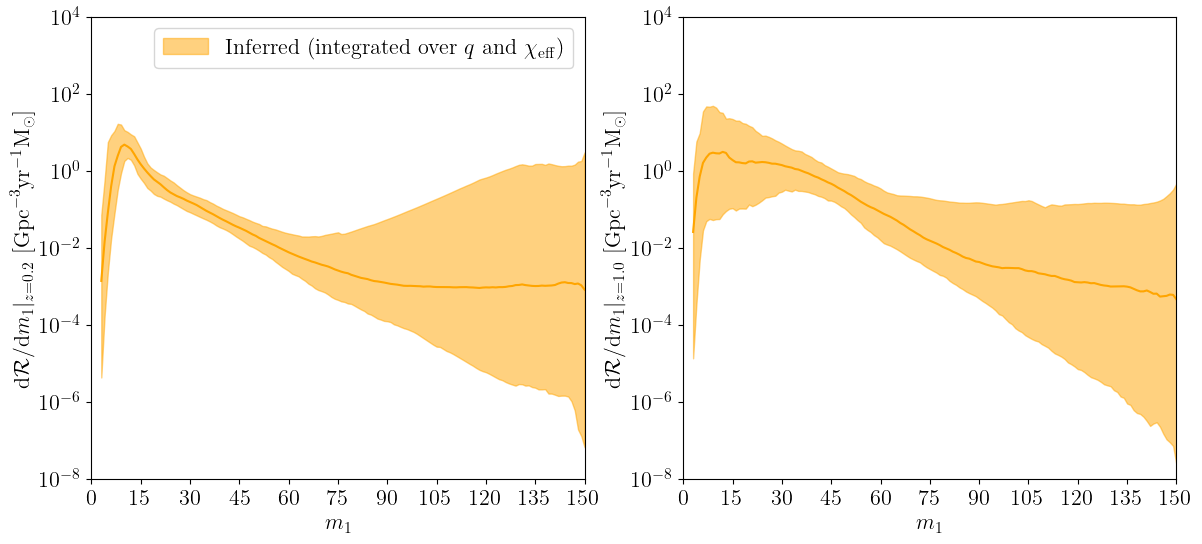

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(14,6))

z_values_toplot = [0.2,1.0]
ymins = [1e-8, 1e-8]
ymaxs = [1e4, 1e4]

for n,zeval in enumerate(z_values_toplot):
    ax = axes[n]
    # redshift_factor_strong_bbh_o4b = (1 + zeval)**(strong_bbh_O4b.get_hyperparameter_samples(hyperparameters=['lamb']))
    # ax.plot(strong_bbh_O4b_m1_grid, np.quantile(redshift_factor_strong_bbh_o4b * strong_bbh_O4b_Rm1, 0.5, axis=0),
    #         color=spm_color, label='Default BBH, GWTC-5.0', lw=1.5, zorder=5)
    # ax.fill_between(strong_bbh_O4b_m1_grid,
    #                 np.quantile(redshift_factor_strong_bbh_o4b * strong_bbh_O4b_Rm1, 0.05, axis=0),
    #                 np.quantile(redshift_factor_strong_bbh_o4b * strong_bbh_O4b_Rm1, 0.95, axis=0),
    #                 color=spm_color, edgecolor=None, alpha=0.5, zorder=5,
    #                )
    # redshift_factor_pixelpop_m1 = (1 + zeval)**(m1m2_pixelpop.get_hyperparameter_samples(hyperparameters=['lamb']))
    # ax.step(np.exp(pixelpop_m1_grid), np.quantile(redshift_factor_pixelpop_m1 * pixelpop_Rm1 /np.exp(pixelpop_m1_grid) , 0.5, axis = 0),
    #         color=wpm_color, label='PixelPop, GWTC-5.0', lw=2.0, zorder=2)
    # ax.fill_between(np.exp(pixelpop_m1_grid),
    #                 np.quantile(redshift_factor_pixelpop_m1 * pixelpop_Rm1 / np.exp(pixelpop_m1_grid) , 0.05, axis = 0),
    #                 np.quantile(redshift_factor_pixelpop_m1 * pixelpop_Rm1 / np.exp(pixelpop_m1_grid), 0.95, axis = 0),
    #                 color=wpm_color, edgecolor=None, alpha=0.4, step='pre', zorder=2,
    #                )

    ## Compute log-rate over a grid with fixed redshift ##
    m1_grid0 = np.linspace(m1_min, m1_max, 148)
    z_grid0 = np.array([zeval])
    q_grid0 = np.linspace(q_min,q_max,21)
    chi_grid0 = np.linspace(chi_eff_min, chi_eff_max, 21)
    dm1_0 = m1_grid0[1] - m1_grid0[0]
    dq_0 = q_grid0[1] - q_grid0[0]
    dchi_0 = chi_grid0[1] - chi_grid0[0]
    
    X0, Y0, Z0, T0 = np.meshgrid(m1_grid0, z_grid0, q_grid0, chi_grid0)
    grid0 = np.c_[X0.ravel(), Y0.ravel(), Z0.ravel(), T0.ravel()]
    
    comov0 = (1 + zeval) / (
            4 * np.pi * Tobs * Planck15.differential_comoving_volume(zeval).to(u.Gpc**3 / u.sr).value
        )

    log_rate0 = np.zeros((num_triangulations, grid0.shape[0]))

    for ind, tri_ind in enumerate(tqdm(selected_tris)):
        this_delo = delaunaytor.CPUDelaunayInterpolator()
        this_delo.triangulate(all_triangulations[tri_ind])
        log_rate0[ind] = this_delo.interpolate(grid0)
        
    square_rate0 = log_rate0.reshape(num_triangulations, m1_grid0.shape[0], q_grid0.shape[0], chi_grid0.shape[0])
    
    dRdm1_zeval = np.sum(np.exp(square_rate0) *comov0, axis=(2,3)) *dq_0 *dchi_0
    low_dRdm1 = np.quantile(dRdm1_zeval, 0.05, axis=0)
    median_dRdm1 = np.quantile(dRdm1_zeval, 0.5, axis=0)
    high_dRdm1 = np.quantile(dRdm1_zeval, 0.95, axis=0)
    
    ax.plot(m1_grid0, median_dRdm1, color="orange")
    ax.fill_between(m1_grid0, low_dRdm1, high_dRdm1,
                    color="orange", alpha=0.5,
                    label=r'Inferred (integrated over $q$ and $\chi_\mathrm{eff}$)',
                    )

    # dRdm1_prior_zeval = np.sum(np.exp(square_rate_prior[:,zeval_ind,:,:]) 
    #                            *to_comoving_volume[zeval_ind], axis=2) *dq
    # low_dRdm1_prior = np.quantile(dRdm1_prior_zeval, 0.05, axis=0)
    # median_dRdm1_prior = np.quantile(dRdm1_prior_zeval, 0.5, axis=0)
    # high_dRdm1_prior = np.quantile(dRdm1_prior_zeval, 0.95, axis=0)
    # ax.plot(m1_grid, median_dRdm1_prior, color="forestgreen", alpha=0.5)
    # ax.fill_between(m1_grid, low_dRdm1_prior, high_dRdm1_prior,
    #                 color="forestgreen", alpha=0.25,
    #                 label='Induced prior',
    #                 )
    
    ax.set_xlabel(r'$m_1$')
    ax.set_xlim(xmin=m1_min, xmax=m1_max)
    ax.set_xticks(np.linspace(0,m1_max,int(m1_max/15)+1))
    ax.set_ylabel(
        r'$\mathrm{d}\mathcal{R}/\mathrm{d}m_1 |_{z=%.1f}\ [\mathrm{Gpc}^{-3}\mathrm{yr}^{-1}\mathrm{M}_\odot]$' 
        %(zeval),
    )
    ax.set_yscale('log')
    #ax.set_box_aspect(1)
    ax.set_ylim(ymin=ymins[n], ymax=ymaxs[n])

axes[0].legend(loc='best')
plt.show()
plt.close()

In [34]:
# fig, ax = plt.subplots(1, 1, figsize=(6,6))

# ax.plot(strong_bbh_O4b_z_grid, np.quantile(strong_bbh_O4b_Rz, 0.5, axis = 0),
#         color=spm_color, label='Default BBH, GWTC-5.0', lw=1.5, zorder=5)
# ax.fill_between(strong_bbh_O4b_z_grid,
#         np.quantile(strong_bbh_O4b_Rz, 0.05, axis=0),
#         np.quantile(strong_bbh_O4b_Rz, 0.95, axis=0),
#         color=spm_color, edgecolor=None, alpha=0.5, zorder=5)
# # ax.step(pixelpop_z_grid, np.quantile(pixelpop_Rz , 0.5, axis = 0),
# #         color=wpm_color, label='PixelPop, GWTC-5.0', lw=2.0, zorder=2)
# # ax.fill_between(pixelpop_z_grid,
# #         np.quantile(pixelpop_Rz, 0.05, axis = 0),
# #         np.quantile(pixelpop_Rz, 0.95, axis = 0),
# #         color=wpm_color, edgecolor=None, alpha=0.4, step='pre', zorder=2)

# Rz = np.sum(np.exp(square_rate) 
#               *to_comoving_volume[None,:,None,None,None], axis=(2,3,4)) *dq *dm1 *dchi
# low_Rz = np.quantile(Rz, 0.05, axis=0)
# median_Rz = np.quantile(Rz, 0.5, axis=0)
# high_Rz = np.quantile(Rz, 0.95, axis=0)

# ax.plot(z_grid, median_Rz, color="orange")
# ax.fill_between(z_grid, low_Rz, high_Rz,
#                 color="orange", alpha=0.5,
#                 label=r'Inferred (integrated over $m_1$, $q$,'+'\n'+r'and $\chi_\mathrm{eff}$)',
#                 )

# # Rz_prior = np.sum(np.exp(square_rate_prior) 
# #                     *to_comoving_volume[None,:,None,None], axis=(2,3)) *dq *dm1
# # low_Rz_prior = np.quantile(Rz_prior, 0.05, axis=0)
# # median_Rz_prior = np.quantile(Rz_prior, 0.5, axis=0)
# # high_Rz_prior = np.quantile(Rz_prior, 0.95, axis=0)
# # ax.plot(z_grid, median_Rz_prior, color="forestgreen", alpha=0.5)
# # ax.fill_between(z_grid, low_Rz_prior, high_Rz_prior,
# #                 color="forestgreen", alpha=0.25,
# #                 label='Induced prior',
# #                 )


# ax.set_xlabel(r'$z$')
# ax.set_xlim(xmin=z_min, xmax=z_max)
# ax.set_xticks(np.linspace(0,z_max,int(z_max*10)+1)[::2])
# ax.set_ylabel(r'$\mathcal{R}(z)\ [\mathrm{Gpc}^{-3}\mathrm{yr}^{-1}]$')
# ax.set_yscale('log')
# ax.legend(loc='best')
# #ax.set_box_aspect(1)
# ax.set_ylim(ymin=1e-3, ymax=1e5)

# plt.show()
# plt.close()

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1000/1000 [00:45<00:00, 21.87it/s]


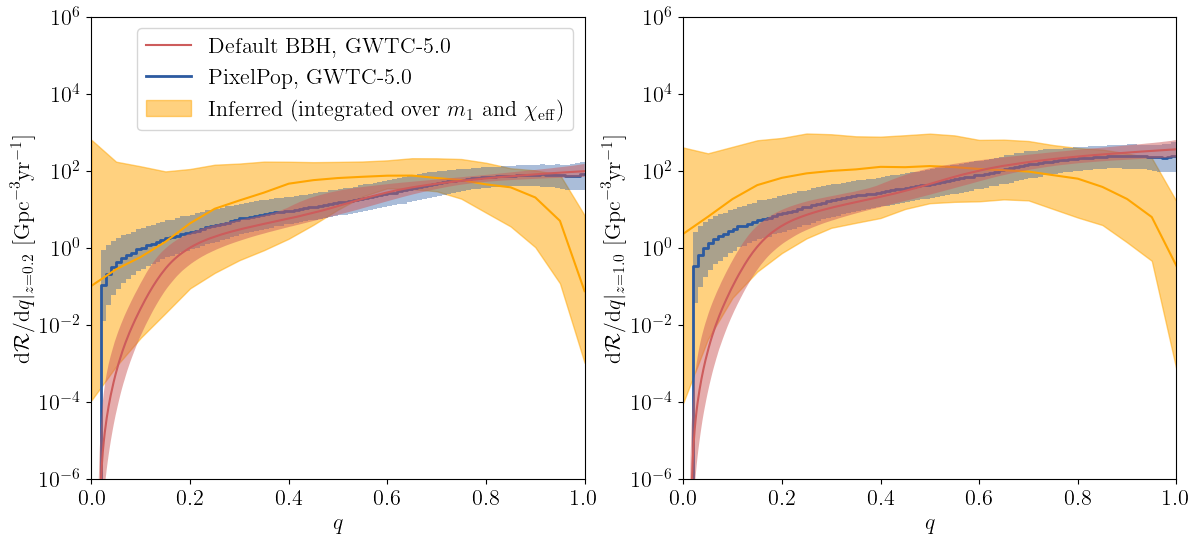

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(14,6))

z_values_toplot = [0.2,1.0]
ymins = [1e-6, 1e-6]
ymaxs = [1e6, 1e6]


for n,zeval in enumerate(z_values_toplot):
    ax = axes[n]
    redshift_factor_strong_bbh_o4b = (1 + zeval)**(strong_bbh_O4b.get_hyperparameter_samples(hyperparameters=['lamb']))
    ax.plot(strong_bbh_O4b_q_grid, np.quantile(redshift_factor_strong_bbh_o4b * strong_bbh_O4b_Rq, 0.5, axis=0),
            color=spm_color, label='Default BBH, GWTC-5.0', lw=1.5, zorder=5)
    ax.fill_between(strong_bbh_O4b_q_grid,
                    np.quantile(redshift_factor_strong_bbh_o4b * strong_bbh_O4b_Rq, 0.05, axis=0),
                    np.quantile(redshift_factor_strong_bbh_o4b * strong_bbh_O4b_Rq, 0.95, axis=0),
                    color=spm_color, edgecolor=None, alpha=0.5, zorder=5,
                   )
    redshift_factor_pixelpop_q = (1 + zeval)**(m1q_pixelpop.get_hyperparameter_samples(hyperparameters=['lamb']))
    ax.step(pixelpop_q_grid, np.quantile(redshift_factor_pixelpop_q * pixelpop_Rq, 0.5, axis = 0),
            color=wpm_color, label='PixelPop, GWTC-5.0', lw=2.0, zorder=2)
    ax.fill_between(pixelpop_q_grid,
                    np.quantile(redshift_factor_pixelpop_q * pixelpop_Rq, 0.05, axis = 0),
                    np.quantile(redshift_factor_pixelpop_q * pixelpop_Rq, 0.95, axis = 0),
                    color=wpm_color, edgecolor=None, alpha=0.4, step='pre', zorder=2,
                   )

    ## Compute log-rate over a grid with fixed redshift ##
    m1_grid0 = np.linspace(m1_min, m1_max, 148)
    z_grid0 = np.array([zeval])
    q_grid0 = np.linspace(q_min,q_max,21)
    chi_grid0 = np.linspace(chi_eff_min, chi_eff_max, 21)
    dm1_0 = m1_grid0[1] - m1_grid0[0]
    dq_0 = q_grid0[1] - q_grid0[0]
    dchi_0 = chi_grid0[1] - chi_grid0[0]
    
    X0, Y0, Z0, T0 = np.meshgrid(m1_grid0, z_grid0, q_grid0, chi_grid0)
    grid0 = np.c_[X0.ravel(), Y0.ravel(), Z0.ravel(), T0.ravel()]
    
    comov0 = (1 + zeval) / (
            4 * np.pi * Tobs * Planck15.differential_comoving_volume(zeval).to(u.Gpc**3 / u.sr).value
        )

    log_rate0 = np.zeros((num_triangulations, grid0.shape[0]))

    for ind, tri_ind in enumerate(tqdm(selected_tris)):
        this_delo = delaunaytor.CPUDelaunayInterpolator()
        this_delo.triangulate(all_triangulations[tri_ind])
        log_rate0[ind] = this_delo.interpolate(grid0)
        
    square_rate0 = log_rate0.reshape(num_triangulations, m1_grid0.shape[0], q_grid0.shape[0], chi_grid0.shape[0])
    
    dRdq_zeval = np.sum(np.exp(square_rate0) *comov0, axis=(1,3)) *dm1_0 *dchi_0
    low_dRdq = np.quantile(dRdq_zeval, 0.05, axis=0)
    median_dRdq = np.quantile(dRdq_zeval, 0.5, axis=0)
    high_dRdq = np.quantile(dRdq_zeval, 0.95, axis=0)
    
    ax.plot(q_grid0, median_dRdq, color="orange")
    ax.fill_between(q_grid0, low_dRdq, high_dRdq,
                    color="orange", alpha=0.5,
                    label=r'Inferred (integrated over $m_1$ and $\chi_\mathrm{eff}$)',
                    )
    
    # dRdq_prior_zeval = np.sum(np.exp(square_rate_prior[:,zeval_ind,:,:]) 
    #                            *to_comoving_volume[zeval_ind], axis=1) *dm1
    # low_dRdq_prior = np.quantile(dRdq_prior_zeval, 0.05, axis=0)
    # median_dRdq_prior = np.quantile(dRdq_prior_zeval, 0.5, axis=0)
    # high_dRdq_prior = np.quantile(dRdq_prior_zeval, 0.95, axis=0)
    # ax.plot(q_grid, median_dRdq_prior, color="forestgreen", alpha=0.5)
    # ax.fill_between(q_grid, low_dRdq_prior, high_dRdq_prior,
    #                 color="forestgreen", alpha=0.25,
    #                 label='Induced prior',
    #                 )
    
    ax.set_xlabel(r'$q$')
    ax.set_xlim(xmin=q_min, xmax=q_max)
    ax.set_xticks(np.linspace(0,1,6))
    ax.set_ylabel(
        r'$\mathrm{d}\mathcal{R}/\mathrm{d}q |_{z=%.1f}\ [\mathrm{Gpc}^{-3}\mathrm{yr}^{-1}]$' 
        %(zeval)
    )
    ax.set_yscale('log')
    #ax.set_box_aspect(1)
    ax.set_ylim(ymin=ymins[n], ymax=ymaxs[n])

axes[0].legend(loc='best')
plt.show()
plt.close()

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1000/1000 [00:49<00:00, 20.16it/s]


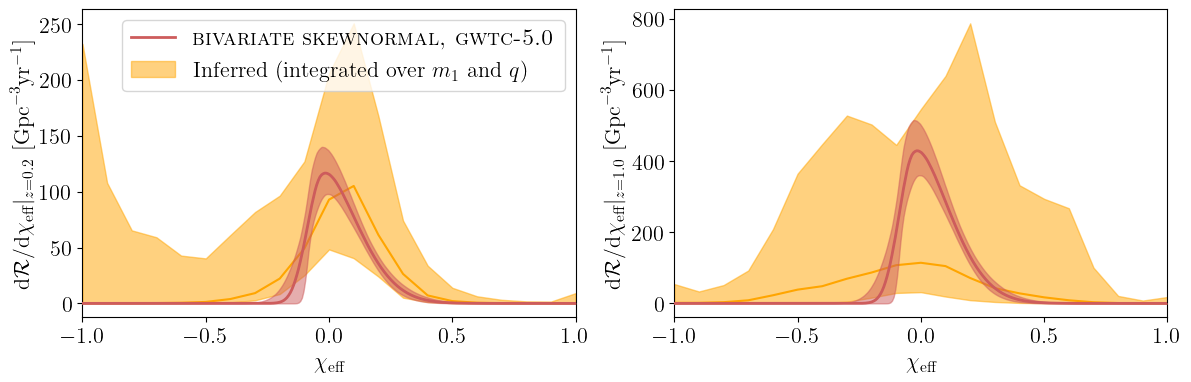

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(14,4))

z_values_toplot = [0.2,1.0]
ymins = [1e-6, 1e-6]
ymaxs = [1e6, 1e6]


for n,zeval in enumerate(z_values_toplot):
    ax = axes[n]
    
    median_Rz = np.quantile(strong_bbh_O4b_Rz, 0.5, axis = 0)[np.argmin(np.abs(strong_bbh_O4b_z_grid-zeval))]
    ax.plot(skewnorm_chieff_grid, median_Rz*np.quantile(skewnorm_p_chieff.T, 0.5, axis = 1), 
             color=spm_color, label='$\\textsc{bivariate skewnormal, gwtc-5.0}$', zorder=5, lw=2.0)  
    ax.fill_between(skewnorm_chieff_grid, 
                    median_Rz*np.quantile(skewnorm_p_chieff.T, 0.05, axis = 1),
                    median_Rz*np.quantile(skewnorm_p_chieff.T, 0.95, axis = 1), 
                    color=spm_color, alpha=0.5, zorder=5,
                   ) 
    # ax.step(pixelpop_chieff_grid, np.quantile(pixelpop_chieff, 0.5, axis = 0), 
    #          color=wpm_color, label='$\\textsc{PixelPop, gwtc-5.0}$', zorder=1, lw=2.0) 
    # ax.fill_between(pixelpop_chieff_grid, 
    #                 np.quantile(pixelpop_chieff, 0.05, axis = 0), 
    #                 np.quantile(pixelpop_chieff, 0.95, axis = 0), 
    #                 color=wpm_color, edgecolor=None, alpha=0.5, step='pre', zorder=1,
    #                )

    ## Compute log-rate over a grid with fixed redshift ##
    m1_grid0 = np.linspace(m1_min, m1_max, 148)
    z_grid0 = np.array([zeval])
    q_grid0 = np.linspace(q_min,q_max,21)
    chi_grid0 = np.linspace(chi_eff_min, chi_eff_max, 21)
    dm1_0 = m1_grid0[1] - m1_grid0[0]
    dq_0 = q_grid0[1] - q_grid0[0]
    dchi_0 = chi_grid0[1] - chi_grid0[0]
    
    X0, Y0, Z0, T0 = np.meshgrid(m1_grid0, z_grid0, q_grid0, chi_grid0)
    grid0 = np.c_[X0.ravel(), Y0.ravel(), Z0.ravel(), T0.ravel()]
    
    comov0 = (1 + zeval) / (
            4 * np.pi * Tobs * Planck15.differential_comoving_volume(zeval).to(u.Gpc**3 / u.sr).value
        )

    log_rate0 = np.zeros((num_triangulations, grid0.shape[0]))

    for ind, tri_ind in enumerate(tqdm(selected_tris)):
        this_delo = delaunaytor.CPUDelaunayInterpolator()
        this_delo.triangulate(all_triangulations[tri_ind])
        log_rate0[ind] = this_delo.interpolate(grid0)
        
    square_rate0 = log_rate0.reshape(num_triangulations, m1_grid0.shape[0], q_grid0.shape[0], chi_grid0.shape[0])
    
    dRdchi_zeval = np.sum(np.exp(square_rate0) *comov0, axis=(1,2)) *dm1_0 *dq_0
    low_dRdchi = np.quantile(dRdchi_zeval, 0.05, axis=0)
    median_dRdchi = np.quantile(dRdchi_zeval, 0.5, axis=0)
    high_dRdchi = np.quantile(dRdchi_zeval, 0.95, axis=0)
    
    ax.plot(chi_grid0, median_dRdchi, color="orange")
    ax.fill_between(chi_grid0, low_dRdchi, high_dRdchi,
                    color="orange", alpha=0.5,
                    label=r'Inferred (integrated over $m_1$ and $q$)',
                    )
    
    # dRdchi_prior_zeval = np.sum(np.exp(square_rate_prior[:,zeval_ind,:,:,:]) 
    #                            *to_comoving_volume[zeval_ind], axis=(1,2)) *dm1 *dq
    # low_dRdchi_prior = np.quantile(dRdchi_prior_zeval, 0.05, axis=0)
    # median_dRdchi_prior = np.quantile(dRdchi_prior_zeval, 0.5, axis=0)
    # high_dRdchi_prior = np.quantile(dRdchi_prior_zeval, 0.95, axis=0)
    # ax.plot(chi_grid, median_dRdchi_prior, color="forestgreen", alpha=0.5)
    # ax.fill_between(chi_grid, low_dRdm1_prior, high_dRdm1_prior,
    #                 color="forestgreen", alpha=0.25,
    #                 label='Induced prior',
    #                 )


    ax.set_xlabel(r'$\chi_\mathrm{eff}$')
    ax.set_xlim([chi_eff_min, chi_eff_max])
    ax.set_ylabel(
        r'$\mathrm{d}\mathcal{R}/\mathrm{d}\chi_\mathrm{eff} |_{z=%.1f}\ [\mathrm{Gpc}^{-3}\mathrm{yr}^{-1}]$' 
        %(zeval)
    )
    #ax.set_yscale('log')

axes[0].legend(loc='best')
plt.show()
plt.close()

# 95% - 5% CI 

In [37]:
# median = np.quantile(square_rate, 0.5, axis=0)
# low = np.quantile(square_rate, 0.05, axis=0)
# high = np.quantile(square_rate, 0.95, axis=0)

In [38]:
linestyles = ['solid', 'dashed', 'dotted', 'dashdot', (0, (5, 5))]  # You can add more or customize
n_contours = min(5, len(linestyles))

cmap=plt.get_cmap('viridis')
norm = mpl.colors.Normalize(vmin=-20, vmax=5)

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1000/1000 [00:09<00:00, 100.56it/s]


-14.985273183152277 -1.0025860900621835


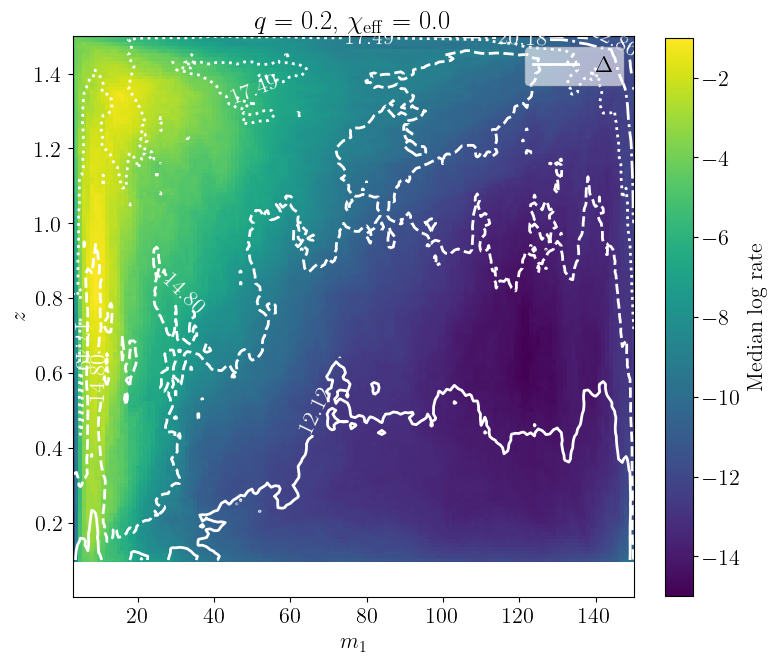

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1000/1000 [00:09<00:00, 106.16it/s]


-15.15180299133364 2.9656698274844775


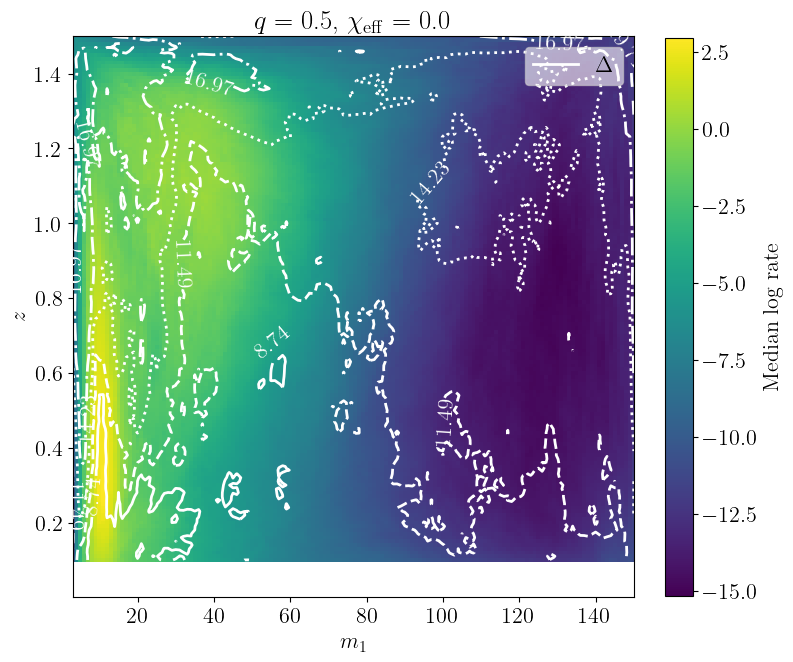

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1000/1000 [00:09<00:00, 105.14it/s]


-14.78493609491727 1.493772639801266


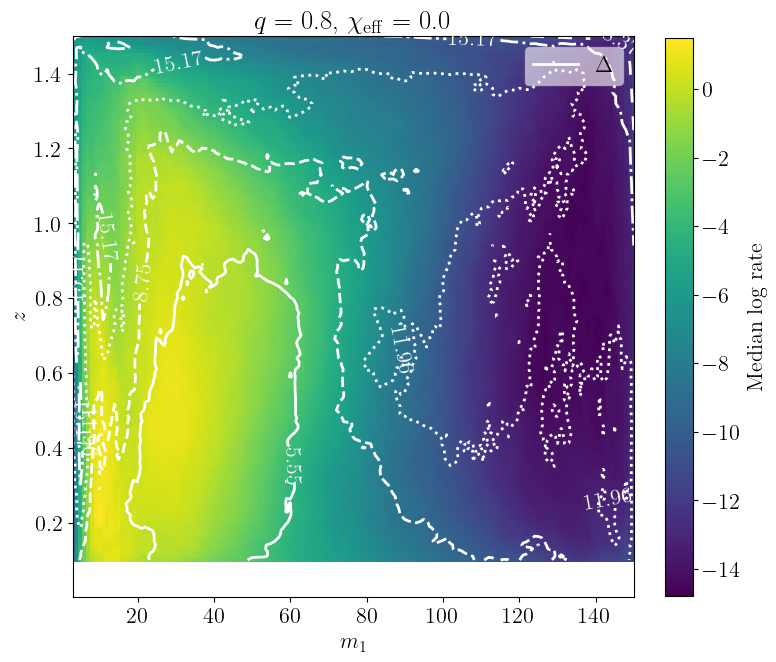

In [39]:

chieval = 0.0

for qeval in [0.2, 0.5, 0.8]:
    fig, ax = plt.subplots(figsize=(8,8))
    ax.set(title=r"$q$ = %.1f, $\chi_\mathrm{eff}$ = %.1f" %(qeval,chieval))

    m1_grid0 = np.linspace(m1_min, m1_max, 148)
    z_grid0 = np.linspace(0.1, z_max, 141)
    q_grid0 = np.array([qeval])
    chi_grid0 = np.array([chieval])
    
    X0, Y0, Z0, T0 = np.meshgrid(m1_grid0, z_grid0, q_grid0, chi_grid0)
    grid0 = np.c_[X0.ravel(), Y0.ravel(), Z0.ravel(), T0.ravel()]
    
    comov0 = (1 + z_grid0) / (
            4 * np.pi * Tobs * Planck15.differential_comoving_volume(z_grid0).to(u.Gpc**3 / u.sr).value
        )

    log_rate0 = np.zeros((num_triangulations, grid0.shape[0]))

    for ind, tri_ind in enumerate(tqdm(selected_tris)):
        this_delo = delaunaytor.CPUDelaunayInterpolator()
        this_delo.triangulate(all_triangulations[tri_ind])
        log_rate0[ind] = this_delo.interpolate(grid0)
        
    square_rate0 = log_rate0.reshape(num_triangulations, z_grid0.shape[0], m1_grid0.shape[0])

    median0 = np.quantile(square_rate0, 0.5, axis=0)
    low0 = np.quantile(square_rate0, 0.05, axis=0)
    high0 = np.quantile(square_rate0, 0.95, axis=0)
    rate0 = median0 +np.log(comov0[:,None])
    print(rate0.min(), rate0.max())

    c = ax.pcolormesh(m1_grid0, z_grid0, rate0,
                      cmap=cmap, 
                      #norm=norm,
                     )
    
    # Calculate the difference
    diff0 = high0 - low0
    
    # Define contour levels (choose appropriate values for your data)
    levels = np.linspace(np.nanmin(diff0), np.nanmax(diff0), n_contours + 2)[1:-1]  # avoid min/max

    # Plot contours with different linestyles
    contours = ax.contour(
        m1_grid0, z_grid0, diff0, 
        levels=levels, 
        linestyles=linestyles[:n_contours],
        linewidths=2, 
        colors='white'
    )
    ax.clabel(contours, fmt="%.2f")
    ax.plot([],[], c='white', lw=2, label=r'$\Delta$')

    # events_at_q = np.abs(event_barycenters[:,2]-qeval) /qeval < 0.1
    # ax.scatter(event_barycenters[events_at_q,0], event_barycenters[events_at_q,1],
    #            c='k', marker='*', s=7**2, zorder=2,
    #            label='Event barycenters',
    #           )

    # injections_at_q = np.abs(detected_injections[:,2]-qeval) /qeval < 0.001
    # ax.scatter(detected_injections[injections_at_q,0], detected_injections[injections_at_q,1],
    #            c='r', marker='d', s=4**2, zorder=1,
    #            label='Detected injections',
    #           )
    ax.set_xlabel(r'$m_1$')
    ax.set_xlim(m1_min,m1_max)
    ax.set_ylabel(r'$z$')
    ax.set_ylim(z_min,z_max)
    ax.legend(loc='upper right', framealpha=0.6)
    ax.set_box_aspect(1)

    cbar = fig.colorbar(c, ax=ax, fraction=0.045)
    cbar.set_label(r'Median log rate')
    
    plt.show()
    plt.close()

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1000/1000 [00:08<00:00, 119.80it/s]


-14.204893765543321 3.232211319686548


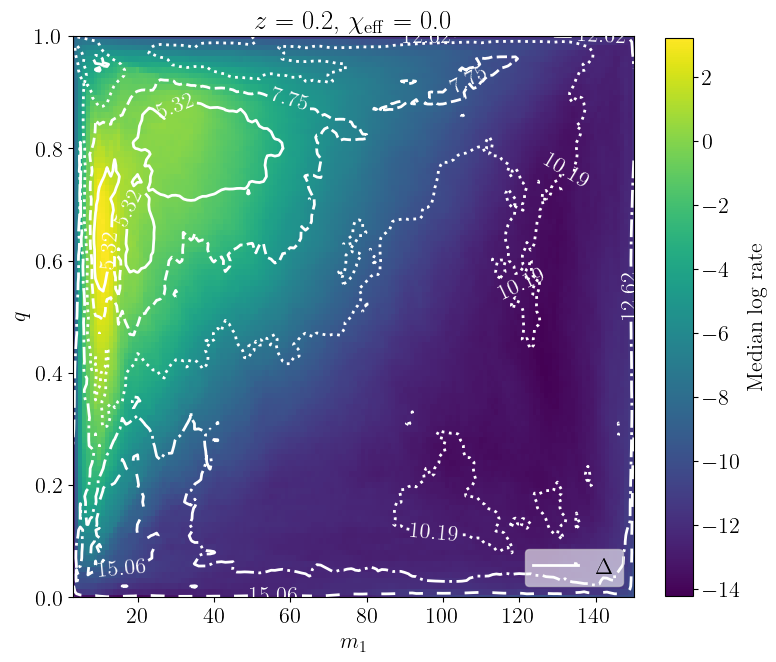

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1000/1000 [00:07<00:00, 128.46it/s]


-15.00944193692288 2.8814912437225617


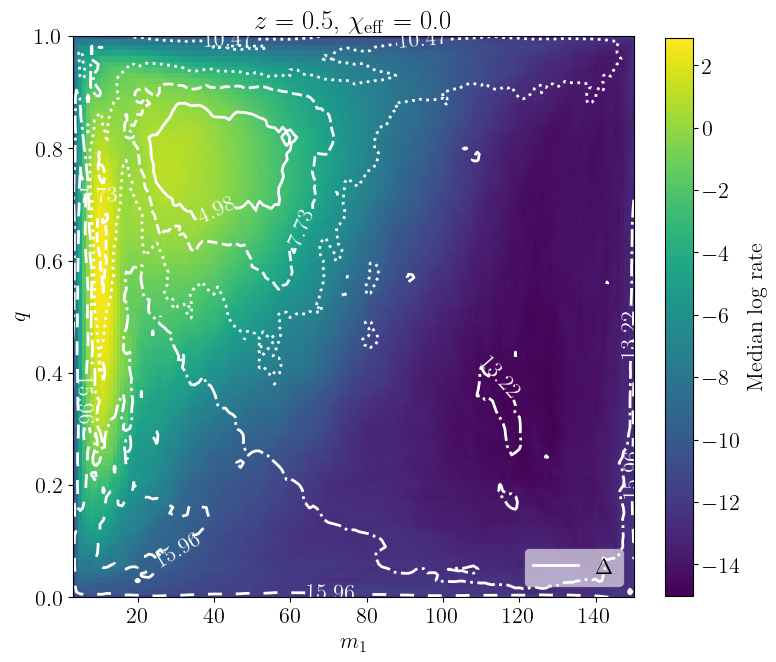

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1000/1000 [00:07<00:00, 128.50it/s]


-15.319884840384582 1.2906678322057772


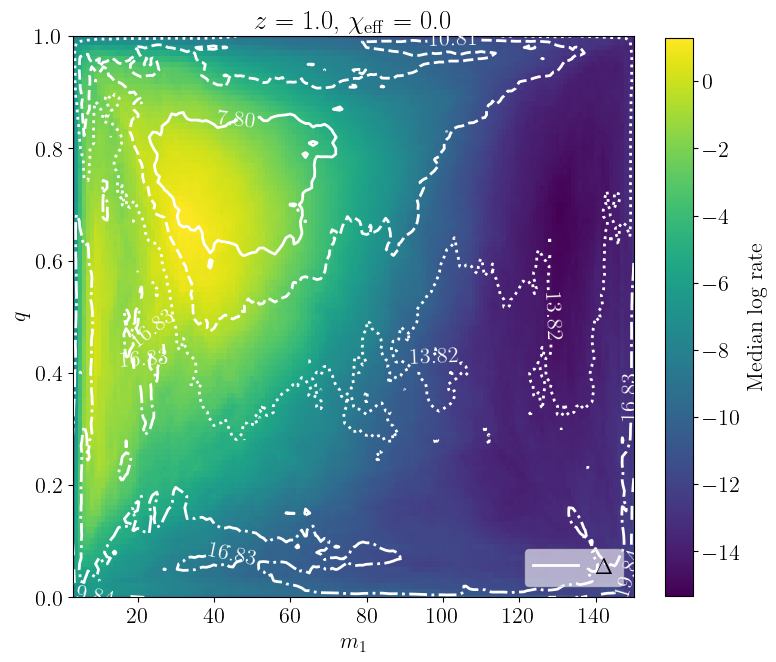

In [40]:

chieval = 0.0

for zeval in [0.2, 0.5, 1.0]:
    fig, ax = plt.subplots(figsize=(8,8))
    ax.set(title=r"$z$ = %.1f, $\chi_\mathrm{eff}$ = %.1f" %(zeval,chieval))

    m1_grid0 = np.linspace(m1_min, m1_max, 148)
    z_grid0 = np.array([zeval])
    q_grid0 = np.linspace(q_min,q_max,101)
    chi_grid0 = np.array([chieval])
    
    X0, Y0, Z0, T0 = np.meshgrid(m1_grid0, z_grid0, q_grid0, chi_grid0)
    grid0 = np.c_[X0.ravel(), Y0.ravel(), Z0.ravel(), T0.ravel()]
    
    comov0 = (1 + zeval) / (
            4 * np.pi * Tobs * Planck15.differential_comoving_volume(zeval).to(u.Gpc**3 / u.sr).value
        )

    log_rate0 = np.zeros((num_triangulations, grid0.shape[0]))

    for ind, tri_ind in enumerate(tqdm(selected_tris)):
        this_delo = delaunaytor.CPUDelaunayInterpolator()
        this_delo.triangulate(all_triangulations[tri_ind])
        log_rate0[ind] = this_delo.interpolate(grid0)
        
    square_rate0 = log_rate0.reshape(num_triangulations, m1_grid0.shape[0], q_grid0.shape[0])

    median0 = np.quantile(square_rate0, 0.5, axis=0)
    low0 = np.quantile(square_rate0, 0.05, axis=0)
    high0 = np.quantile(square_rate0, 0.95, axis=0)
    rate0 = median0.T +np.log(comov0)
    print(rate0.min(), rate0.max())
    
    c = ax.pcolormesh(m1_grid0, q_grid0, rate0,
                      cmap=cmap, 
                      #norm=norm,
                     )

    
    # Calculate the difference
    diff0 = high0 - low0
    
    # Define contour levels (choose appropriate values for your data)
    levels = np.linspace(np.nanmin(diff0), np.nanmax(diff0), n_contours + 2)[1:-1]  # avoid min/max

    # Plot contours with different linestyles
    contours = ax.contour(
        m1_grid0, q_grid0, diff0.T, 
        levels=levels, 
        linestyles=linestyles[:n_contours],
        linewidths=2, 
        colors='white'
    )
    ax.clabel(contours, fmt="%.2f")
    ax.plot([],[], c='white', lw=2, label=r'$\Delta$')

    # events_at_z = np.abs(event_barycenters[:,1]-zeval) /zeval < 0.1
    # ax.scatter(event_barycenters[events_at_z,0], event_barycenters[events_at_z,2],
    #            c='k', marker='*', s=7**2, zorder=2,
    #            label='Event barycenters',
    #           )

    # injections_at_z = np.abs(detected_injections[:,1]-zeval) /zeval < 0.001
    # ax.scatter(detected_injections[injections_at_z,0], detected_injections[injections_at_z,2],
    #            c='r', marker='d', s=4**2, zorder=1,
    #            label='Detected injections',
    #           )
    ax.set_xlabel(r'$m_1$')
    ax.set_xlim(m1_min,m1_max)
    ax.set_ylabel(r'$q$')
    ax.set_ylim(q_min,q_max)
    ax.legend(loc='lower right', framealpha=0.6)
    ax.set_box_aspect(1)

    cbar = fig.colorbar(c, ax=ax, fraction=0.045)
    cbar.set_label(r'Median log rate')
    
    plt.show()
    plt.close()

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1000/1000 [00:08<00:00, 119.01it/s]


-13.737648970344726 1.4109565417369963


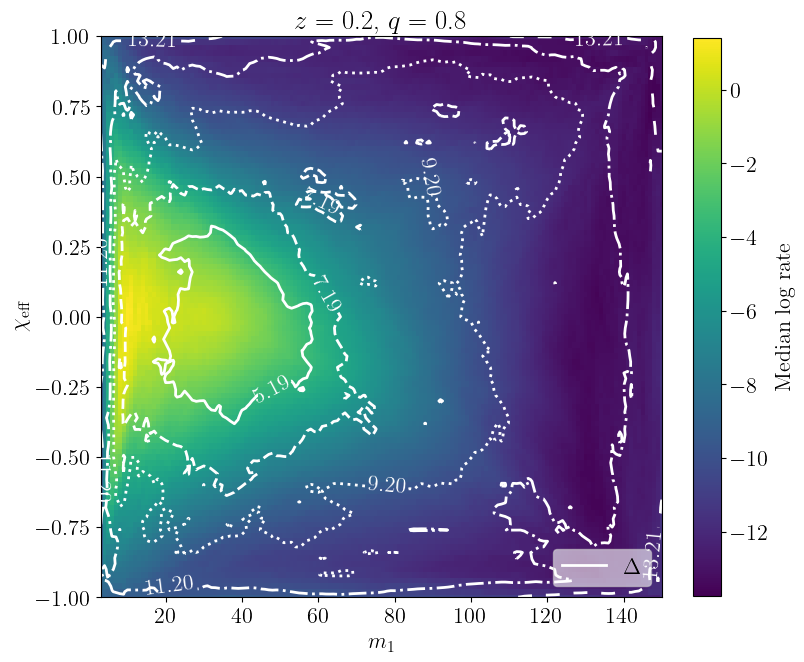

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1000/1000 [00:08<00:00, 112.84it/s]


-14.941111136191822 1.1562434997153241


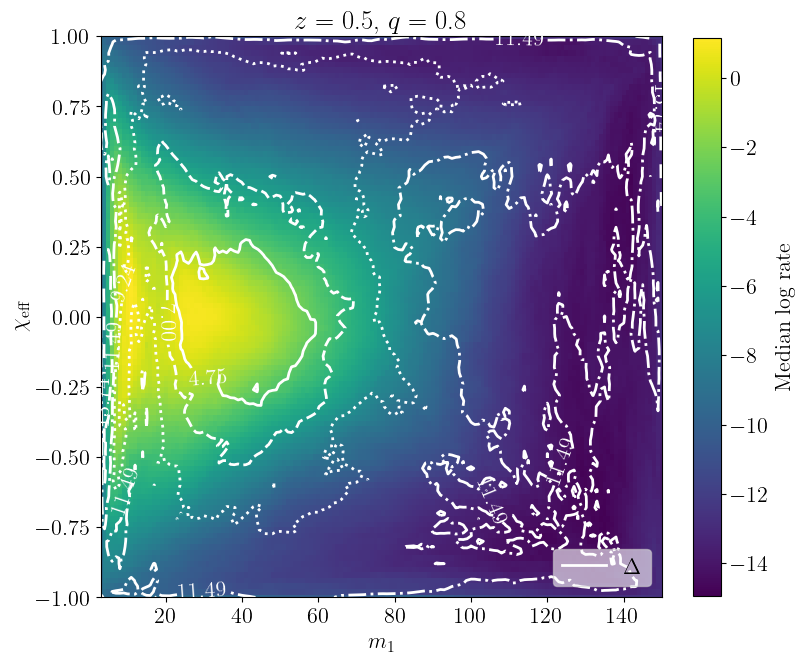

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1000/1000 [00:07<00:00, 134.58it/s]


-15.323923841381262 0.28989461678135076


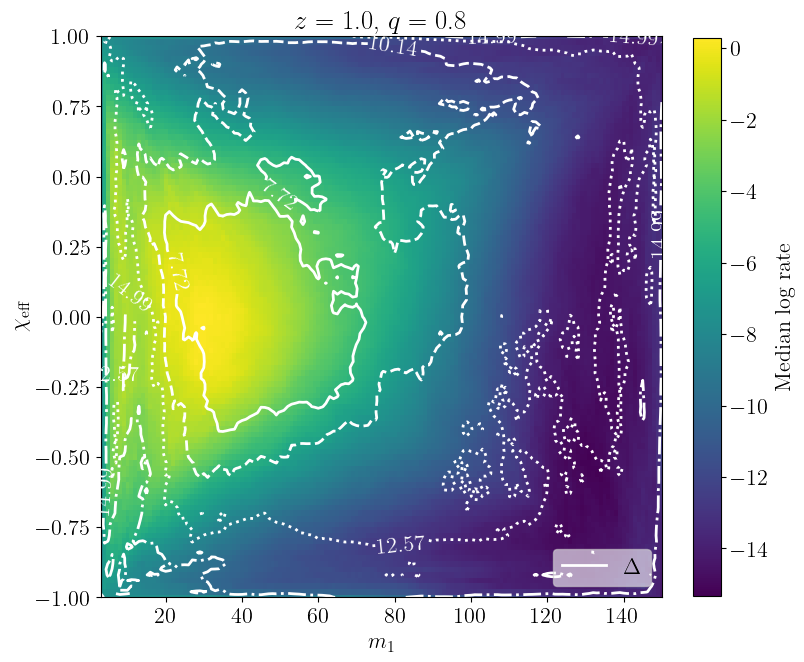

In [41]:

qeval = 0.8

for zeval in [0.2, 0.5, 1.0]:
    fig, ax = plt.subplots(figsize=(8,8))
    ax.set(title=r"$z$ = %.1f, $q$ = %.1f" %(zeval,qeval))

    m1_grid0 = np.linspace(m1_min, m1_max, 148)
    z_grid0 = np.array([zeval])
    q_grid0 = np.array([qeval])
    chi_grid0 = np.linspace(chi_eff_min, chi_eff_max, 101)
    
    X0, Y0, Z0, T0 = np.meshgrid(m1_grid0, z_grid0, q_grid0, chi_grid0)
    grid0 = np.c_[X0.ravel(), Y0.ravel(), Z0.ravel(), T0.ravel()]
    
    comov0 = (1 + zeval) / (
            4 * np.pi * Tobs * Planck15.differential_comoving_volume(zeval).to(u.Gpc**3 / u.sr).value
        )

    log_rate0 = np.zeros((num_triangulations, grid0.shape[0]))

    for ind, tri_ind in enumerate(tqdm(selected_tris)):
        this_delo = delaunaytor.CPUDelaunayInterpolator()
        this_delo.triangulate(all_triangulations[tri_ind])
        log_rate0[ind] = this_delo.interpolate(grid0)
        
    square_rate0 = log_rate0.reshape(num_triangulations, m1_grid0.shape[0], chi_grid0.shape[0])

    median0 = np.quantile(square_rate0, 0.5, axis=0)
    low0 = np.quantile(square_rate0, 0.05, axis=0)
    high0 = np.quantile(square_rate0, 0.95, axis=0)
    rate0 = median0.T +np.log(comov0)
    print(rate0.min(), rate0.max())
    
    c = ax.pcolormesh(m1_grid0, chi_grid0, rate0,
                      cmap=cmap, 
                      #norm=norm,
                     )

    
    # Calculate the difference
    diff0 = high0 - low0

    # Define contour levels (choose appropriate values for your data)
    levels = np.linspace(np.nanmin(diff0), np.nanmax(diff0), n_contours + 2)[1:-1]  # avoid min/max

    # Plot contours with different linestyles
    contours = ax.contour(
        m1_grid0, chi_grid0, diff0.T, 
        levels=levels, 
        linestyles=linestyles[:n_contours],
        linewidths=2, 
        colors='white'
    )
    ax.clabel(contours, fmt="%.2f")
    ax.plot([],[], c='white', lw=2, label=r'$\Delta$')

    # events_at_z = np.abs(event_barycenters[:,1]-zeval) /zeval < 0.1
    # ax.scatter(event_barycenters[events_at_z,0], event_barycenters[events_at_z,2],
    #            c='k', marker='*', s=7**2, zorder=2,
    #            label='Event barycenters',
    #           )

    # injections_at_z = np.abs(detected_injections[:,1]-zeval) /zeval < 0.001
    # ax.scatter(detected_injections[injections_at_z,0], detected_injections[injections_at_z,2],
    #            c='r', marker='d', s=4**2, zorder=1,
    #            label='Detected injections',
    #           )
    ax.set_xlabel(r'$m_1$')
    ax.set_xlim(m1_min,m1_max)
    ax.set_ylabel(r'$\chi_\mathrm{eff}$')
    ax.set_ylim(chi_eff_min,chi_eff_max)
    ax.legend(loc='lower right', framealpha=0.6)
    ax.set_box_aspect(1)

    cbar = fig.colorbar(c, ax=ax, fraction=0.045)
    cbar.set_label(r'Median log rate')
    
    plt.show()
    plt.close()

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1000/1000 [00:08<00:00, 119.31it/s]


-13.201003177144848 2.7529227849214193


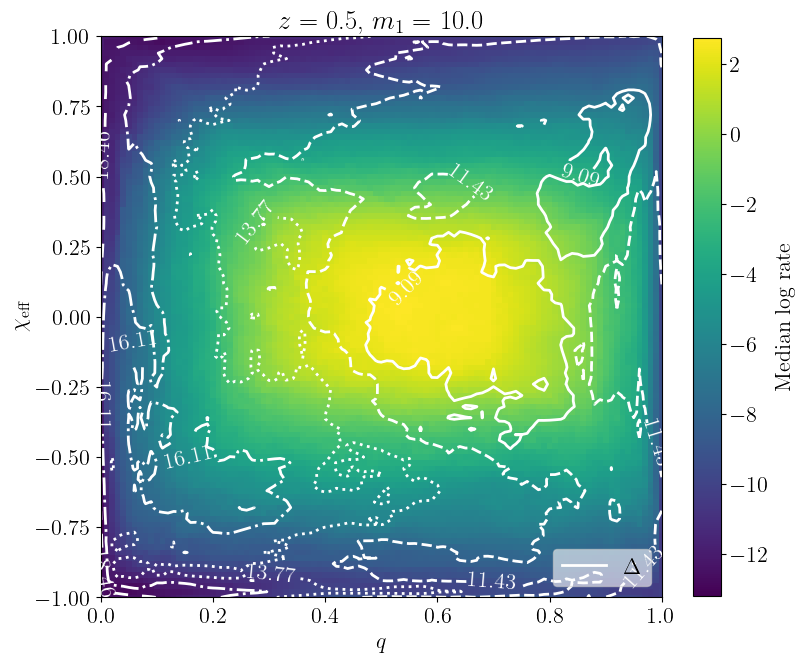

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1000/1000 [00:07<00:00, 128.51it/s]


-13.62426591758379 0.6486644188024115


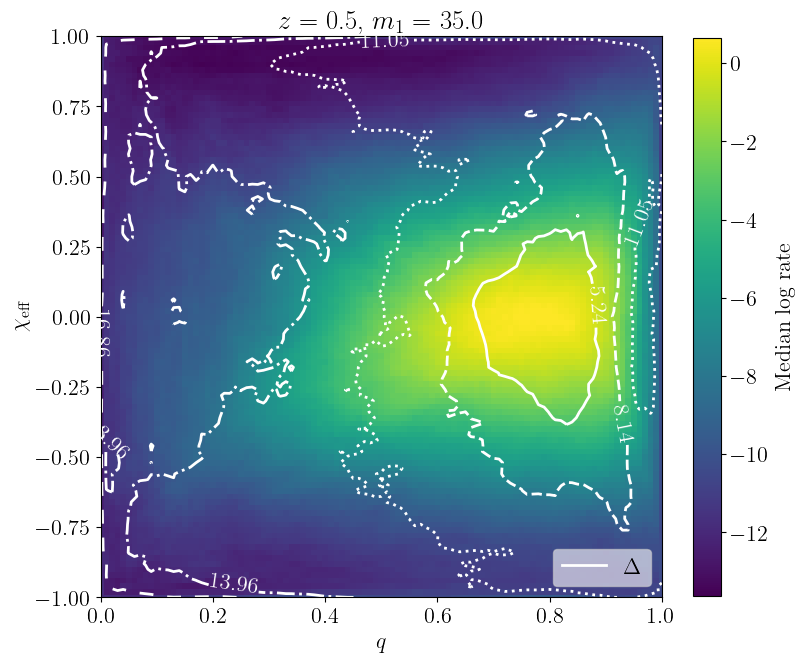

In [42]:

zeval = 0.5

for m1eval in [10.0, 35.0]:
    fig, ax = plt.subplots(figsize=(8,8))
    ax.set(title=r"$z$ = %.1f, $m_1$ = %.1f" %(zeval,m1eval))

    m1_grid0 = np.array([m1eval])
    z_grid0 = np.array([zeval])
    q_grid0 = np.linspace(q_min,q_max,101)
    chi_grid0 = np.linspace(chi_eff_min, chi_eff_max, 101)
    
    X0, Y0, Z0, T0 = np.meshgrid(m1_grid0, z_grid0, q_grid0, chi_grid0)
    grid0 = np.c_[X0.ravel(), Y0.ravel(), Z0.ravel(), T0.ravel()]
    
    comov0 = (1 + zeval) / (
            4 * np.pi * Tobs * Planck15.differential_comoving_volume(zeval).to(u.Gpc**3 / u.sr).value
        )

    log_rate0 = np.zeros((num_triangulations, grid0.shape[0]))

    for ind, tri_ind in enumerate(tqdm(selected_tris)):
        this_delo = delaunaytor.CPUDelaunayInterpolator()
        this_delo.triangulate(all_triangulations[tri_ind])
        log_rate0[ind] = this_delo.interpolate(grid0)
        
    square_rate0 = log_rate0.reshape(num_triangulations, q_grid0.shape[0], chi_grid0.shape[0])

    median0 = np.quantile(square_rate0, 0.5, axis=0)
    low0 = np.quantile(square_rate0, 0.05, axis=0)
    high0 = np.quantile(square_rate0, 0.95, axis=0)
    rate0 = median0.T +np.log(comov0)
    print(rate0.min(), rate0.max())
    
    c = ax.pcolormesh(q_grid0, chi_grid0, rate0,
                      cmap=cmap, 
                      #norm=norm,
                     )

    
    # Calculate the difference
    diff0 = high0 - low0

    # Define contour levels (choose appropriate values for your data)
    levels = np.linspace(np.nanmin(diff0), np.nanmax(diff0), n_contours + 2)[1:-1]  # avoid min/max

    # Plot contours with different linestyles
    contours = ax.contour(
        q_grid0, chi_grid0, diff0.T, 
        levels=levels, 
        linestyles=linestyles[:n_contours],
        linewidths=2, 
        colors='white'
    )
    ax.clabel(contours, fmt="%.2f")
    ax.plot([],[], c='white', lw=2, label=r'$\Delta$')

    # events_at_z = np.abs(event_barycenters[:,1]-zeval) /zeval < 0.1
    # ax.scatter(event_barycenters[events_at_z,0], event_barycenters[events_at_z,2],
    #            c='k', marker='*', s=7**2, zorder=2,
    #            label='Event barycenters',
    #           )

    # injections_at_z = np.abs(detected_injections[:,1]-zeval) /zeval < 0.001
    # ax.scatter(detected_injections[injections_at_z,0], detected_injections[injections_at_z,2],
    #            c='r', marker='d', s=4**2, zorder=1,
    #            label='Detected injections',
    #           )
    ax.set_xlabel(r'$q$')
    ax.set_xlim(q_min,q_max)
    ax.set_ylabel(r'$\chi_\mathrm{eff}$')
    ax.set_ylim(chi_eff_min,chi_eff_max)
    ax.legend(loc='lower right', framealpha=0.6)
    ax.set_box_aspect(1)

    cbar = fig.colorbar(c, ax=ax, fraction=0.045)
    cbar.set_label(r'Median log rate')
    
    plt.show()
    plt.close()

### LVK results in 2D

In [ ]:
# Downselect to a reasonable number of hyperparameter samples
num_pop_LVK = 1000
inds_LVK = np.random.choice(np.arange(strong_bbh_O4b_Rz.shape[0]), size=num_pop_LVK, replace=False)

In [ ]:
# rate_pop_LVK = np.zeros((num_pop_LVK, len(strong_bbh_O4b_z_grid), len(strong_bbh_O4b_m1_grid)))
# for ind,pop_ind in enumerate(tqdm(inds_LVK)):
#     int_dRdm1 = np.trapezoid(x=strong_bbh_O4b_m1_grid, y=strong_bbh_O4b_Rm1[pop_ind])
#     rate_pop_LVK[ind] = np.outer(strong_bbh_O4b_Rz[pop_ind], strong_bbh_O4b_Rm1[pop_ind] /int_dRdm1)
# median_LVK = np.quantile(rate_pop_LVK, 0.5, axis=0)

In [ ]:
# cmap=plt.get_cmap('viridis')
# norm = mpl.colors.Normalize(vmin=-15, vmax=3)

# fig, ax = plt.subplots(figsize=(6,6))
# c = ax.pcolormesh(strong_bbh_O4b_m1_grid, strong_bbh_O4b_z_grid, np.log(median_LVK),
#                   cmap=cmap, norm=norm,
#                  )
# cbar = fig.colorbar(c, ax=ax, fraction=0.045)
# cbar.set_label(r'Median log rate - LVK')


# ax.set_xlabel('$m_1$')
# ax.set_xlim(m1_min, m1_max)
# ax.set_ylabel('$z$')
# ax.set_ylim(z_min, z_max)
# #ax.legend(loc='lower right', framealpha=0.6)
# ax.set_box_aspect(1)

# plt.show()
# plt.close()

# Delta

In [ ]:
diff = high-low
interp_delta = RegularGridInterpolator((z_grid, m1_grid, q_grid), diff, bounds_error=False, fill_value=np.nan)

In [ ]:
qeval = 0.8
qeval_ind = np.argmin(np.abs(q_grid-qeval))

cmap=plt.get_cmap('magma')
norm=mpl.colors.Normalize(vmin=np.min(diff), vmax=np.max(diff))
fig,ax=plt.subplots(figsize=(6,6))
ax.set(title=f"q = {q_grid[qeval_ind]:.1f}")

samples_try=np.zeros((5000,3))

samples_try[:,0]=np.random.uniform(m1_min,m1_max,5000)
samples_try[:,1]=np.random.uniform(z_min,z_max,5000)
samples_try[:,2]=qeval

sc=ax.scatter(samples_try[:,0],samples_try[:,1],
              c=interp_delta(samples_try[:,(1,0,2)]),
              cmap=cmap, norm=norm,
             )
    
ax.set_xlabel(r'$m_1$')
ax.set_ylabel(r'$z$')
#ax.legend(loc='lower right', framealpha=0.6)
ax.set_box_aspect(1)

cbar = fig.colorbar(sc, ax=ax, fraction=0.045)
cbar.set_label(r'$\Delta$')

plt.show()
plt.close()

In [ ]:
delta_levels = np.linspace(np.min(diff), np.max(diff), 25)[1:-1]
print(delta_levels)

In [ ]:
samples_per_tri = 1_000
ndraw = 10_000

ints_delta={}
ints_delta_LVK={}
volume = np.prod(corners.max(axis=0) - corners.min(axis=0))
to_cosmo = interp1d(z_grid, to_comoving_volume, fill_value='extrapolate')
for delta in delta_levels:
    print(delta)
    nprop=0
    nkeep=0
    nkeep_old=0

    proposals=np.zeros((ndraw,3))
    cosmo_fac=np.zeros(ndraw)

    while nkeep<ndraw:
        
        new_points=np.zeros((ndraw-nkeep,3))
        new_points[:,0]=np.random.uniform(m1_min,m1_max,ndraw-nkeep)
        new_points[:,1]=np.random.uniform(z_min,z_max,ndraw-nkeep)
        new_points[:,2]=np.random.uniform(q_min,q_max,ndraw-nkeep)

        nprop+=ndraw-nkeep       
        inds_proposal_keep=np.argwhere(interp_delta(new_points[:,(1,0,2)])<delta)[:,0]
        nkeep+=len(inds_proposal_keep)
        proposals[nkeep_old:nkeep]=new_points[inds_proposal_keep]
        cosmo_fac=to_cosmo(proposals[:,1])
        nkeep_old+=len(inds_proposal_keep)

    frac_kept = nkeep / nprop

    ints_delta[delta]=np.zeros(num_triangulations)
    ints_delta_LVK[delta]=np.zeros(num_pop_LVK)

    for ind, tri_ind in enumerate(tqdm(selected_tris)):
        this_delo = delaunaytor.CPUDelaunayInterpolator()
        this_delo.triangulate(all_triangulations[tri_ind])
        #mean_fx = (np.exp(this_delo.interpolate(proposals))).mean()
        mean_fx = np.mean(np.exp(this_delo.interpolate(proposals)) *cosmo_fac)
        ints_delta[delta][ind] = mean_fx * frac_kept * volume

    for ind, tri_ind in enumerate(tqdm(inds_LVK)):
        pdf_m1 = interp1d(x=strong_bbh_O4b_m1_grid, 
                          y=strong_bbh_O4b_Rm1[tri_ind] /strong_bbh_O4b_Rz[tri_ind,0], 
                          fill_value="extrapolate",
                         )
        rate_z = interp1d(x=strong_bbh_O4b_z_grid, 
                          y=strong_bbh_O4b_Rz[ind], 
                          fill_value="extrapolate",
                         )
        pdf_q = interp1d(x=strong_bbh_O4b_q_grid, 
                         y=strong_bbh_O4b_Rq[tri_ind] /strong_bbh_O4b_Rz[tri_ind,0], 
                         fill_value="extrapolate",
                        )
        mean_Nx = (
            pdf_m1(proposals[:,0])
            *rate_z(proposals[:,1])
            *pdf_q(proposals[:,2])
        ).mean()       
        ints_delta_LVK[delta][ind] = mean_Nx * frac_kept * volume

In [ ]:
fig, ax = plt.subplots(figsize=(6,6))

median_LVK = [ np.median(ints_delta_LVK[delta]) for delta in delta_levels]
low_LVK = [ np.quantile(ints_delta_LVK[delta], 0.05) for delta in delta_levels]
high_LVK = [ np.quantile(ints_delta_LVK[delta], 0.95) for delta in delta_levels]
ax.plot(delta_levels, median_LVK, "--", color="black", zorder=3, label="LVK population results")
ax.fill_between(delta_levels, low_LVK, high_LVK, 
                alpha=0.4, color="black")

median_delta = [ np.median(ints_delta[delta]) for delta in delta_levels]
low_delta = [ np.quantile(ints_delta[delta], 0.05) for delta in delta_levels]
high_delta = [ np.quantile(ints_delta[delta], 0.95) for delta in delta_levels]
ax.plot(delta_levels, median_delta, label='Inferred')
ax.fill_between(delta_levels, low_delta, high_delta, alpha=0.4)

ax.errorbar(delta_levels[-1]*1.05, median_prior, np.array([[median_prior-low_prior,high_prior-median_prior]]).T,
            color='firebrick', alpha=0.6, linewidth=2, capsize=6, fmt='.',
            label="Prior",
           )

# np.savez("3D_volume_delta.np", kl=kl_levels, median=median, low=low, high=high)
ax.set_xlabel(r'$\Delta$')
ax.set_ylabel(r'$\int\int\int_\Delta\ \mathcal{R}(m_1,z,q)\mathrm{d}m_1\mathrm{d}z\mathrm{d}q$')
ax.set_yscale('log')
#ax.set_ylim(ymin=1e1, ymax=1e5)

ax.legend(loc='lower right')
ax.set_box_aspect(1)
# plt.savefig("3D_volume_delta")
plt.show()
plt.close()

# KL divergences

In [ ]:
m1_grid_coarse = np.linspace(m1_min, m1_max, 19)
z_grid_coarse = np.linspace(0.1, z_max, 20)
q_grid_coarse = np.linspace(q_min, q_max, 21)

X_coarse, Y_coarse, Z_coarse = np.meshgrid(m1_grid_coarse, z_grid_coarse, q_grid_coarse)
grid_coarse = np.c_[X_coarse.ravel(), Y_coarse.ravel(), Z_coarse.ravel()]

dm1_coarse = m1_grid_coarse[1] - m1_grid_coarse[0]
dz_coarse = z_grid_coarse[1] - z_grid_coarse[0]
dq_coarse = q_grid_coarse[1] - q_grid_coarse[0]

to_comoving_volume_coarse = (1 + z_grid_coarse) / (
        4 * np.pi * Tobs * Planck15.differential_comoving_volume(z_grid_coarse).to(u.Gpc**3 / u.sr).value
    )

In [ ]:
log_rate_coarse = np.zeros((num_triangulations, grid_coarse.shape[0]))

for ind, tri_ind in enumerate(tqdm(selected_tris)):
    this_delo = delaunaytor.CPUDelaunayInterpolator()
    this_delo.triangulate(all_triangulations[tri_ind])
    log_rate_coarse[ind] = this_delo.interpolate(grid_coarse)
    
square_rate_coarse = log_rate_coarse.reshape(num_triangulations, z_grid_coarse.shape[0], m1_grid_coarse.shape[0], q_grid_coarse.shape[0])

In [ ]:
nsamples_prior = 1_000
log_rate_prior_coarse = np.zeros((nsamples_prior, grid_coarse.shape[0]))

for i in tqdm(range(nsamples_prior)):
    nleaves_i = np.random.randint(nvertices_min, nvertices_max)
    tri_i = np.zeros((nleaves_i+offset,ndim+1))
    tri_i[:offset,:-1] = corners
    tri_i[offset:,0] = np.random.uniform(m1_min, m1_max, nleaves_i)
    tri_i[offset:,1] = np.random.uniform(z_min, z_max, nleaves_i)
    tri_i[offset:,2] = np.random.uniform(q_min, q_max, nleaves_i)
    tri_i[:,-1] = np.random.uniform(w_min, w_max, nleaves_i+offset)
   
    this_delo = delaunaytor.CPUDelaunayInterpolator()
    this_delo.triangulate(tri_i)
    log_rate_prior_coarse[i] = this_delo.interpolate(grid_coarse)

square_rate_prior_coarse = log_rate_prior_coarse.reshape(nsamples_prior, z_grid_coarse.shape[0], m1_grid_coarse.shape[0], q_grid_coarse.shape[0])

In [ ]:
kl_divs=np.zeros((len(z_grid_coarse),len(m1_grid_coarse),len(q_grid_coarse)))

for i,j,k in product(range(z_grid_coarse.shape[0]),range(m1_grid_coarse.shape[0]),range(q_grid_coarse.shape[0])):
    kl_divs[i,j,k] = kl_divergence_kde(square_rate_coarse[:,i,j,k],square_rate_prior_coarse[:,i,j,k])

In [ ]:
interp_kl = RegularGridInterpolator((z_grid_coarse, m1_grid_coarse, q_grid_coarse), kl_divs, bounds_error=False, fill_value=np.nan)

In [ ]:

linestyles = ['solid', 'dashed', 'dotted', 'dashdot', (0, (5, 5))]  # You can add more or customize

cmap=plt.get_cmap('viridis')
norm = mpl.colors.Normalize(vmin=-15, vmax=1)

for qeval in [0.2, 0.5, 0.8]:
    qeval_ind = np.argmin(np.abs(q_grid-qeval))
    fig, ax = plt.subplots(figsize=(8,8))
    ax.set(title=f"q = {qeval:.1f}")

    c = ax.pcolormesh(m1_grid, z_grid, median[:, :, qeval_ind] +np.log(to_comoving_volume[:,None]),
                      cmap=cmap, norm=norm,
                     )

    # Define contour levels (choose appropriate values for your data)
    n_contours = min(5, len(linestyles))
    levels_kl = np.linspace(np.nanmin(kl_divs), np.nanmax(kl_divs), n_contours + 2)[1:-1]  # avoid min/max

    Xz0, Yz0, Zz0 = np.meshgrid(m1_grid, z_grid, np.array([q_grid[qeval_ind]]))
    # grid_z0 = np.c_[Xz0.ravel(), Yz0.ravel(), Zz0.ravel()]
    grid_z0 = np.c_[Yz0.ravel(), Xz0.ravel(), Zz0.ravel()]

    # Plot contours with different linestyles
    contours_kl = ax.contour(
        m1_grid, z_grid, interp_kl(grid_z0).reshape(len(z_grid),len(m1_grid)), 
        levels=levels_kl, 
        linestyles=linestyles[:n_contours][::-1],
        linewidths=2, 
        colors='black'
    )
    ax.clabel(contours_kl, fmt="%.2f")
    ax.plot([],[], lw=2, color='k', label='KL')

    ## Overplot contours of diff log-rate ## 35
    # Calculate the difference
    diff = high[:, :, qeval_ind] - low[:, :, qeval_ind]
    # Define contour levels (choose appropriate values for your data)
    levels = np.linspace(np.nanmin(diff), np.nanmax(diff), n_contours + 2)[1:-1]  # avoid min/max
    # Plot contours with different linestyles
    contours = ax.contour(
        m1_grid, z_grid, diff, 
        levels=levels, 
        linestyles=linestyles[:n_contours],
        linewidths=2, 
        colors='white'
    )
    ax.clabel(contours, fmt="%.2f")
    ax.plot([],[], c='white', lw=2, label=r'$\Delta$')

    # events_at_q = np.abs(event_barycenters[:,2]-qeval) /qeval < 0.1
    # ax.scatter(event_barycenters[events_at_q,0], event_barycenters[events_at_q,1],
    #            c='k', marker='*', s=7**2, zorder=2,
    #            label='Event barycenters',
    #           )

    # injections_at_q = np.abs(detected_injections[:,2]-qeval) /qeval < 0.001
    # ax.scatter(detected_injections[injections_at_q,0], detected_injections[injections_at_q,1],
    #            c='r', marker='d', s=4**2, zorder=1,
    #            label='Detected injections',
    #           )
    ax.set_xlabel('$m_1$')
    ax.set_xlim(m1_min,m1_max)
    ax.set_ylabel('$z$')
    ax.set_ylim(z_min,z_max)
    ax.legend(loc='upper right', framealpha=0.6)
    ax.set_box_aspect(1)

    cbar = fig.colorbar(c, ax=ax, fraction=0.045)
    cbar.set_label(r'Median log rate')
    
    plt.show()
    plt.close()

In [ ]:

linestyles = ['solid', 'dashed', 'dotted', 'dashdot', (0, (5, 5))]  # You can add more or customize

cmap=plt.get_cmap('viridis')
norm = mpl.colors.Normalize(vmin=-15, vmax=1)

for zeval in [0.2, 0.5, 1.0]:
    zeval_ind = np.argmin(np.abs(z_grid-zeval))
    fig, ax = plt.subplots(figsize=(8,8))
    ax.set(title=f"z = {zeval:.1f}")   
    
    c = ax.pcolormesh(m1_grid, q_grid, median[zeval_ind, :, :].T +np.log(to_comoving_volume[zeval_ind]),
                      cmap=cmap, norm=norm,
                     )

    # Define contour levels (choose appropriate values for your data)
    n_contours = min(5, len(linestyles))
    levels_kl = np.linspace(np.nanmin(kl_divs), np.nanmax(kl_divs), n_contours + 2)[1:-1]  # avoid min/max

    Xz0, Yz0, Zz0 = np.meshgrid(m1_grid, np.array([z_grid[zeval_ind]]), q_grid)
    # grid_z0 = np.c_[Xz0.ravel(), Yz0.ravel(), Zz0.ravel()]
    grid_z0 = np.c_[Yz0.ravel(), Xz0.ravel(), Zz0.ravel()]

    # Plot contours with different linestyles
    contours_kl = ax.contour(
        m1_grid, q_grid, interp_kl(grid_z0).reshape(len(m1_grid),len(q_grid)).T, 
        levels=levels_kl, 
        linestyles=linestyles[:n_contours][::-1],
        linewidths=2, 
        colors='black'
    )
    ax.clabel(contours_kl, fmt="%.2f")
    ax.plot([],[], lw=2, color='k', label='KL')

    
    # Calculate the difference
    diff = high[zeval_ind, :, :] - low[zeval_ind, :, :]

    # Define contour levels (choose appropriate values for your data)
    n_contours = min(5, len(linestyles))
    levels = np.linspace(np.nanmin(diff), np.nanmax(diff), n_contours + 2)[1:-1]  # avoid min/max

    # Plot contours with different linestyles
    contours = ax.contour(
        m1_grid, q_grid, diff.T, 
        levels=levels, 
        linestyles=linestyles[:n_contours],
        linewidths=2, 
        colors='white'
    )
    ax.clabel(contours, fmt="%.2f")
    ax.plot([],[], c='white', lw=2, label=r'$\Delta$')

    events_at_z = np.abs(event_barycenters[:,1]-zeval) /zeval < 0.1
    ax.scatter(event_barycenters[events_at_z,0], event_barycenters[events_at_z,2],
               c='k', marker='*', s=7**2, zorder=2,
               label='Event barycenters',
              )

    injections_at_z = np.abs(detected_injections[:,1]-zeval) /zeval < 0.001
    ax.scatter(detected_injections[injections_at_z,0], detected_injections[injections_at_z,2],
               c='r', marker='d', s=4**2, zorder=1,
               label='Detected injections',
              )
    ax.set_xlabel('$m_1$')
    ax.set_xlim(m1_min,m1_max)
    ax.set_ylabel('$q$')
    ax.set_ylim(q_min,q_max)
    ax.legend(loc='lower right', framealpha=0.6)
    ax.set_box_aspect(1)

    cbar = fig.colorbar(c, ax=ax, fraction=0.045)
    cbar.set_label(r'Median log rate')
    
    plt.show()
    plt.close()

In [ ]:
qeval = 0.8
qeval_ind = np.argmin(np.abs(q_grid-qeval))

cmap=plt.get_cmap('magma')
norm=mpl.colors.Normalize(vmin=np.min(kl_divs), vmax=np.max(kl_divs))
fig,ax=plt.subplots(figsize=(6,6))
ax.set(title=f"q = {q_grid[qeval_ind]:.1f}")

samples_try=np.zeros((5000,3))

samples_try[:,0]=np.random.uniform(m1_min,m1_max,5000)
samples_try[:,1]=np.random.uniform(z_min,z_max,5000)
samples_try[:,2]=qeval

sc=ax.scatter(samples_try[:,0],samples_try[:,1],
              c=interp_kl(samples_try[:,(1,0,2)]),
              cmap=cmap, norm=norm,
             )
    
ax.set_xlabel(r'$m_1$')
ax.set_ylabel(r'$z$')
#ax.legend(loc='lower right', framealpha=0.6)
ax.set_box_aspect(1)

cbar = fig.colorbar(sc, ax=ax, fraction=0.045)
cbar.set_label(r'KL divergence')

plt.show()
plt.close()

In [ ]:
kl_levels = np.linspace(0, np.max(kl_divs), 25)[1:-1]
print(kl_levels)

In [ ]:
samples_per_tri = 1_000
ndraw = 10_000

ints_kl={}
ints_kl_LVK={}
volume = np.prod(corners.max(axis=0) - corners.min(axis=0))
to_cosmo = interp1d(z_grid, to_comoving_volume, fill_value='extrapolate')
for kl in np.flip(kl_levels):
    print(kl)
    nprop=0
    nkeep=0
    nkeep_old=0

    proposals=np.zeros((ndraw,3))
    cosmo_fac=np.zeros(ndraw)
    while nkeep<ndraw:
        
        new_points=np.zeros((ndraw-nkeep,3))
        new_points[:,0]=np.random.uniform(m1_min,m1_max,ndraw-nkeep)
        new_points[:,1]=np.random.uniform(z_min,z_max,ndraw-nkeep)
        new_points[:,2]=np.random.uniform(q_min,q_max,ndraw-nkeep)

        nprop+=ndraw-nkeep
        
        inds_proposal_keep=np.argwhere(interp_kl(new_points[:,(1,0,2)])>kl)[:,0]
        # frac_kept = len(inds_proposal_keep) / len(proposals)
        nkeep+=len(inds_proposal_keep)
        proposals[nkeep_old:nkeep]=new_points[inds_proposal_keep]
        cosmo_fac=to_cosmo(proposals[:,1])

        nkeep_old+=len(inds_proposal_keep)

    frac_kept = nkeep / nprop

    ints_kl[kl]=np.zeros(num_triangulations)
    ints_kl_LVK[kl]=np.zeros(num_pop_LVK)

    for ind, tri_ind in enumerate(tqdm(selected_tris)):
        this_delo = delaunaytor.CPUDelaunayInterpolator()
        this_delo.triangulate(all_triangulations[tri_ind])
        #mean_fx = (np.exp(this_delo.interpolate(proposals))).mean()
        mean_fx = np.mean(np.exp(this_delo.interpolate(proposals)) *cosmo_fac)        
        ints_kl[kl][ind]= mean_fx * frac_kept * volume

    for ind, tri_ind in enumerate(tqdm(inds_LVK)):
        pdf_m1 = interp1d(x=strong_bbh_O4b_m1_grid, 
                          y=strong_bbh_O4b_Rm1[tri_ind] /strong_bbh_O4b_Rz[tri_ind,0], 
                          fill_value="extrapolate",
                         )
        rate_z = interp1d(x=strong_bbh_O4b_z_grid, 
                          y=strong_bbh_O4b_Rz[ind], 
                          fill_value="extrapolate",
                         )
        pdf_q = interp1d(x=strong_bbh_O4b_q_grid, 
                         y=strong_bbh_O4b_Rq[tri_ind] /strong_bbh_O4b_Rz[tri_ind,0], 
                         fill_value="extrapolate",
                        )
        mean_Nx = (
            pdf_m1(proposals[:,0])
            *rate_z(proposals[:,1])
            *pdf_q(proposals[:,2])
        ).mean()       
        ints_kl_LVK[kl][ind] = mean_Nx * frac_kept * volume

In [ ]:
fig, ax = plt.subplots(figsize=(6,6))

median_LVK = [ np.median(ints_kl_LVK[delta]) for delta in kl_levels]
low_LVK = [ np.quantile(ints_kl_LVK[delta], 0.05) for delta in kl_levels]
high_LVK = [ np.quantile(ints_kl_LVK[delta], 0.95) for delta in kl_levels]

ax.plot(kl_levels, median_LVK, "--", color="black", zorder=3, label="LVK population results")
ax.fill_between(kl_levels, low_LVK, high_LVK, 
                alpha=0.4, color="black")

median_kl = [ np.median(ints_kl[kl]) for kl  in kl_levels]
low_kl = [ np.quantile(ints_kl[kl], 0.05) for kl  in kl_levels]
high_kl = [ np.quantile(ints_kl[kl], 0.95) for kl  in kl_levels]

ax.plot(kl_levels, median_kl, label='Inferred')
ax.fill_between(kl_levels, low_kl, high_kl, alpha=0.4)

ax.errorbar(0, median_prior, np.array([[median_prior-low_prior,high_prior-median_prior]]).T,
            color='firebrick', alpha=0.6, linewidth=2, capsize=6, fmt='.',
            label="Prior",
           )

ax.set_xlabel(r'KL')
ax.set_ylabel(r'$\int\int\int_\mathrm{KL}\ \mathcal{R}(m_1,z,q)\mathrm{d}m_1\mathrm{d}z\mathrm{d}q$')
ax.set_yscale('log')
#ax.set_ylim(ymin=1e1, ymax=1e5)

ax.legend(loc='lower left')
ax.set_box_aspect(1)
# plt.savefig("3D_volume_delta")
plt.show()
plt.close()